# Efficient Video Captioning using Adaptive Semantic-Motion Keyframe Selection

**MSVD + BLIP-2 research workflow.** This Colab-compatible notebook implements reproducible video-level splits, frame-selection ablations, T4-conscious LoRA fine-tuning, test-set-safe tuning, automatic evaluation, and artifact tracking. Set the paths in Section 0, run the smoke test, then enable the full experiments deliberately.


# 0. Research Configuration


In [1]:
from dataclasses import dataclass, asdict
from pathlib import Path
import os, json, random, time, gc, math, warnings

@dataclass
class ResearchConfig:
    # Configurable MSVD paths; can be set directly or overridden by environment variables.
    DATA_ROOT: str = os.environ.get("MSVD_DATA_ROOT", "/content/msvd")
    VIDEO_DIR: str = os.environ.get("MSVD_VIDEO_DIR", "YouTubeClips")
    CAPTION_FILE: str = os.environ.get("MSVD_CAPTION_FILE", "captions.csv")
    OUTPUT_DIR: str = os.environ.get("OUTPUT_DIR", "/content/video_captioning_outputs")
    SEED: int = 42
    NUM_CANDIDATE_FRAMES: int = 30
    NUM_SELECTED_FRAMES: int = 8
    ALPHA: float = 0.50
    MIN_TEMPORAL_DISTANCE: float = 0.50  # seconds
    IMAGE_SIZE: int = 224
    BATCH_SIZE: int = 1
    GRADIENT_ACCUMULATION_STEPS: int = 8
    LEARNING_RATE: float = 1e-4
    NUM_EPOCHS: int = 3
    MAX_CAPTION_LENGTH: int = 32
    NUM_WORKERS: int = 0  # GPU preprocessing runs in the main process
    MODEL_NAME: str = "Salesforce/blip2-opt-2.7b"
    TRAIN_RATIO: float = 0.80
    VAL_RATIO: float = 0.10
    TEST_RATIO: float = 0.10
    USE_LORA: bool = True
    USE_4BIT: bool = False  # enable only if bitsandbytes is available and necessary
    SMOKE_TEST_VIDEOS: int = 4
    MAX_TRAIN_VIDEOS: int | None = None  # e.g. 100 for a fast pilot
    RUN_FULL_METADATA: bool = False
    RUN_FINETUNING: bool = False
    RUN_TEST_ABLATIONS: bool = False
    RUN_FRAME_BUDGET_STUDY: bool = False

CFG = ResearchConfig()
ROOT = Path(CFG.DATA_ROOT)
VIDEO_ROOT = ROOT / CFG.VIDEO_DIR
CAPTION_PATH = ROOT / CFG.CAPTION_FILE
OUT = Path(CFG.OUTPUT_DIR)
ARTIFACT_DIRS = ["results/figures", "results/metrics", "results/generated_captions",
                 "results/frame_scores", "results/qualitative", "results/logs",
                 "checkpoints/uniform_baseline", "checkpoints/proposed", "configs", "cache"]
for relative in ARTIFACT_DIRS:
    (OUT / relative).mkdir(parents=True, exist_ok=True)
with open(OUT / "configs/experiment_config.json", "w") as f:
    json.dump(asdict(CFG), f, indent=2)
print(json.dumps(asdict(CFG), indent=2))

{
  "DATA_ROOT": "/content/msvd",
  "VIDEO_DIR": "YouTubeClips",
  "CAPTION_FILE": "captions.csv",
  "OUTPUT_DIR": "/content/video_captioning_outputs",
  "SEED": 42,
  "NUM_CANDIDATE_FRAMES": 30,
  "NUM_SELECTED_FRAMES": 8,
  "ALPHA": 0.5,
  "MIN_TEMPORAL_DISTANCE": 0.5,
  "IMAGE_SIZE": 224,
  "BATCH_SIZE": 1,
  "GRADIENT_ACCUMULATION_STEPS": 8,
  "LEARNING_RATE": 0.0001,
  "NUM_EPOCHS": 3,
  "MAX_CAPTION_LENGTH": 32,
  "NUM_WORKERS": 0,
  "MODEL_NAME": "Salesforce/blip2-opt-2.7b",
  "TRAIN_RATIO": 0.8,
  "VAL_RATIO": 0.1,
  "TEST_RATIO": 0.1,
  "USE_LORA": true,
  "USE_4BIT": false,
  "SMOKE_TEST_VIDEOS": 4,
  "MAX_TRAIN_VIDEOS": null,
  "RUN_FULL_METADATA": false,
  "RUN_FINETUNING": false,
  "RUN_TEST_ABLATIONS": false,
  "RUN_FRAME_BUDGET_STUDY": false
}


# 0b. Architecture Diagram

Renders the proposed pipeline (candidate sampling -> semantic/motion scoring -> fusion -> temporal diversity -> BLIP-2 -> evaluation) and saves it to `results/figures/architecture.png` for the paper.

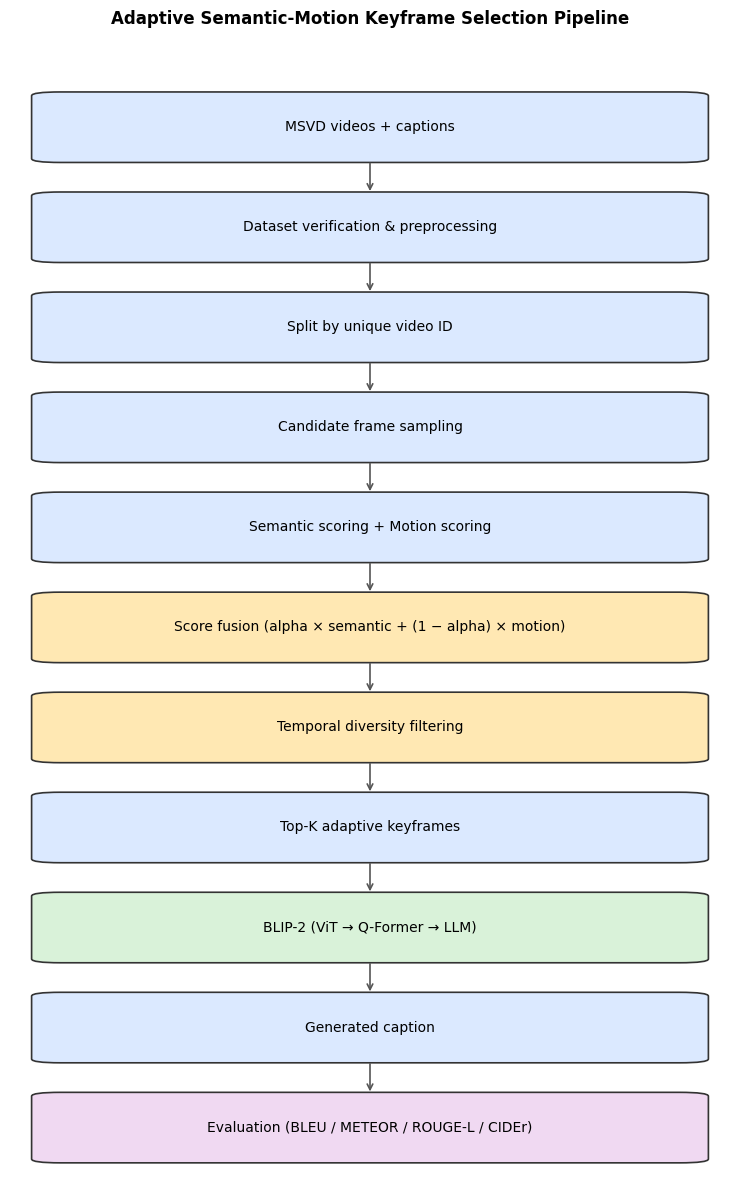

Saved architecture figure: /content/msvd/artifacts/figures/architecture.png


In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

boxes = [
    "MSVD videos + captions",
    "Dataset verification & preprocessing",
    "Split by unique video ID",
    "Candidate frame sampling",
    "Semantic scoring + Motion scoring",
    "Score fusion (alpha × semantic + (1 − alpha) × motion)",
    "Temporal diversity filtering",
    "Top-K adaptive keyframes",
    "BLIP-2 (ViT → Q-Former → LLM)",
    "Generated caption",
    "Evaluation (BLEU / METEOR / ROUGE-L / CIDEr)",
]

fig, ax = plt.subplots(figsize=(7.5, 12))

n = len(boxes)
box_height = 0.7
gap = 0.35
y = n * (box_height + gap)
positions = []

for index, label in enumerate(boxes):
    y -= box_height + gap
    positions.append(y)

    face_color = "#dbe9ff"

    if "fusion" in label.lower() or "diversity" in label.lower():
        face_color = "#ffe8b3"
    elif "BLIP-2" in label:
        face_color = "#d9f2d9"
    elif "Evaluation" in label:
        face_color = "#f0d9f2"

    rectangle = mpatches.FancyBboxPatch(
        (0.05, y),
        0.9,
        box_height,
        boxstyle="round,pad=0.02,rounding_size=0.04",
        linewidth=1.2,
        edgecolor="#333333",
        facecolor=face_color,
    )
    ax.add_patch(rectangle)

    ax.text(
        0.5,
        y + box_height / 2,
        label,
        ha="center",
        va="center",
        fontsize=10,
        wrap=True,
    )

    if index > 0:
        previous_y = positions[index - 1]

        ax.annotate(
            "",
            xy=(0.5, y + box_height),
            xytext=(0.5, previous_y),
            arrowprops={
                "arrowstyle": "->",
                "color": "#555555",
                "lw": 1.2,
            },
        )

ax.set_xlim(0, 1)
ax.set_ylim(
    min(positions) - 0.2,
    max(positions) + box_height + 0.5,
)
ax.axis("off")
ax.set_title(
    "Adaptive Semantic-Motion Keyframe Selection Pipeline",
    fontsize=12,
    fontweight="bold",
    pad=16,
)

# Support either the newer ROOT structure or the earlier OUT structure.
if "ROOT" in globals():
    figure_directory = Path(ROOT) / "artifacts/figures"
elif "OUT" in globals():
    figure_directory = Path(OUT) / "results/figures"
else:
    figure_directory = Path(
        "/content/efficient_video_captioning/artifacts/figures"
    )

figure_directory.mkdir(parents=True, exist_ok=True)
figure_path = figure_directory / "architecture.png"

plt.tight_layout()
fig.savefig(
    figure_path,
    dpi=220,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(fig)

print(f"Saved architecture figure: {figure_path}")

# 1. Environment and GPU Setup


In [4]:
# Optional Drive mount: it is never forced, and local /content data works unchanged.
MOUNT_GOOGLE_DRIVE = False
if MOUNT_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")


In [5]:
import importlib.util, subprocess, sys
required = {"transformers":"transformers==4.45.2", "accelerate":"accelerate==0.34.2", "peft":"peft==0.12.0",
            "cv2":"opencv-python-headless==4.10.0.84", "rouge_score":"rouge-score==0.1.2", "evaluate":"evaluate==0.4.3",
            "wordcloud":"wordcloud==1.9.3", "sentencepiece":"sentencepiece==0.2.0", "nltk":"nltk==3.9.1", "kagglehub":"kagglehub"}
missing = [spec for module, spec in required.items() if importlib.util.find_spec(module) is None]
print("Missing packages:", missing or "none")
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import torch, numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from collections import Counter
from IPython.display import display
warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
seed_everything(CFG.SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU name: {torch.cuda.get_device_name(0)}\nGPU memory: {props.total_memory/2**30:.2f} GB")
else: print("GPU name: CPU (CUDA unavailable)\nGPU memory: n/a")
print(f"CUDA available: {torch.cuda.is_available()}\nPyTorch: {torch.__version__}")
print("OpenCV:", cv2.__version__)

# Persist the exact runtime environment for reproducibility (paper appendix / rerun diffing).
import platform, importlib.metadata as importlib_metadata
version_report = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "opencv": cv2.__version__,
}
for pkg in ["transformers", "accelerate", "peft", "numpy", "pandas", "scikit-learn", "nltk", "rouge-score", "evaluate", "kagglehub"]:
    try: version_report[pkg] = importlib_metadata.version(pkg)
    except importlib_metadata.PackageNotFoundError: version_report[pkg] = "not installed"
with open(OUT / "configs/environment_versions.json", "w") as f: json.dump(version_report, f, indent=2)
with open(OUT / "configs/requirements_report.txt", "w") as f:
    f.write("\n".join(f"{k}=={v}" for k, v in version_report.items()))
print(json.dumps(version_report, indent=2))


Missing packages: ['rouge-score==0.1.2', 'evaluate==0.4.3']
GPU name: Tesla T4
GPU memory: 14.56 GB
CUDA available: True
PyTorch: 2.11.0+cu128
OpenCV: 5.0.0
{
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cu128",
  "cuda_available": true,
  "cuda_version": "12.8",
  "opencv": "5.0.0",
  "transformers": "5.16.1",
  "accelerate": "1.14.0",
  "peft": "0.20.0",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "nltk": "3.9.1",
  "rouge-score": "0.1.2",
  "evaluate": "0.4.3",
  "kagglehub": "1.0.2"
}


# 1b. Dataset Acquisition (Kaggle)

Downloads MSVD from Kaggle (`vtrnanh/msvd-dataset-corpus`) via `kagglehub` when `CFG.DATA_ROOT` is not already populated (e.g. because Drive was mounted above or the dataset was uploaded manually). The downloaded layout is auto-detected so Section 0's `VIDEO_DIR`/`CAPTION_FILE` never need to be hand-edited for the Kaggle mirror.

In [6]:
# Automatic MSVD acquisition via kagglehub. Skips cleanly if DATA_ROOT is already populated
# (e.g. you mounted Drive above) or if USE_KAGGLE_DOWNLOAD is turned off.
USE_KAGGLE_DOWNLOAD = True
KAGGLE_DATASET_ID = "vtrnanh/msvd-dataset-corpus"

def _looks_populated(root: Path) -> bool:
    if not root.exists():
        return False
    video_like = next((p for p in root.rglob("*") if p.suffix.lower() in
                        {".avi", ".mp4", ".webm", ".mov", ".mkv"}), None)
    return video_like is not None

def _autodetect_layout(root: Path):
    """Kaggle mirrors don't always match YouTubeClips/captions.csv exactly, so search for them."""
    video_exts = {".avi", ".mp4", ".webm", ".mov", ".mkv"}
    video_dirs = {}
    for p in root.rglob("*"):
        if p.is_file() and p.suffix.lower() in video_exts:
            video_dirs[p.parent] = video_dirs.get(p.parent, 0) + 1
    video_dir = max(video_dirs, key=video_dirs.get) if video_dirs else None
    caption_candidates = [p for p in root.rglob("*") if p.is_file()
                           and p.suffix.lower() in {".csv", ".tsv", ".json"}
                           and any(s in p.name.lower() for s in ("caption", "description", "corpus", "annotation"))]
    caption_file = caption_candidates[0] if caption_candidates else None
    return video_dir, caption_file

if not _looks_populated(ROOT) and USE_KAGGLE_DOWNLOAD:
    try:
        import kagglehub
        print(f"DATA_ROOT ({ROOT}) has no videos yet -- downloading {KAGGLE_DATASET_ID} via kagglehub...")
        downloaded_path = Path(kagglehub.dataset_download(KAGGLE_DATASET_ID))
        print("kagglehub cached the dataset at:", downloaded_path)
        video_dir, caption_file = _autodetect_layout(downloaded_path)
        if video_dir is None:
            print("WARNING: no video files found in the downloaded dataset; leaving DATA_ROOT unchanged. "
                  "Inspect", downloaded_path, "and set CFG.DATA_ROOT/VIDEO_DIR/CAPTION_FILE manually in Section 0.")
        else:
            ROOT = downloaded_path
            VIDEO_ROOT = video_dir
            CFG.DATA_ROOT = str(ROOT)
            CFG.VIDEO_DIR = str(video_dir.relative_to(ROOT))
            if caption_file is not None:
                CAPTION_PATH = caption_file
                CFG.CAPTION_FILE = str(caption_file.relative_to(ROOT))
            print(f"Resolved VIDEO_DIR -> {VIDEO_ROOT}")
            print(f"Resolved CAPTION_FILE -> {CAPTION_PATH if caption_file else '(not auto-detected; set CFG.CAPTION_FILE manually)'}")
            with open(OUT / "configs/experiment_config.json", "w") as f:
                json.dump(asdict(CFG), f, indent=2)
    except Exception as exc:
        print(f"Kaggle acquisition skipped/failed ({type(exc).__name__}: {exc}). "
              "Set CFG.DATA_ROOT to a manually mounted/uploaded MSVD path in Section 0 instead.")
else:
    print("Using existing DATA_ROOT:" if _looks_populated(ROOT) else "Kaggle download disabled; using DATA_ROOT:", ROOT)


DATA_ROOT (/content/msvd) has no videos yet -- downloading vtrnanh/msvd-dataset-corpus via kagglehub...


100%|██████████| 3.09M/3.09M [00:00<00:00, 25.3MB/s]

Extracting files...


kagglehub cached the dataset at: /root/.cache/kagglehub/datasets/vtrnanh/msvd-dataset-corpus/versions/2


# 2. Dataset Loading and Verification


In [11]:
from pathlib import Path
import datetime as dt
import hashlib
import json
import os
import shutil
import subprocess
import tarfile

ROOT = Path(ROOT)
CONTENT_ROOT = Path("/content")

MSVD_VIDEO_URL = (
    "https://www.cs.utexas.edu/~ml/clamp/"
    "videoDescription/YouTubeClips.tar"
)
MSVD_VIDEO_FILENAME = "YouTubeClips.tar"
MSVD_VIDEO_BYTES = 1_856_460_800
MSVD_VIDEO_MD5 = "9bdb20fcf14d59524a6febca9f6a8d89"
MSVD_EXPECTED_VIDEOS = 1970

RAW_DIRECTORY = ROOT / "data/raw"
VIDEO_ROOT = ROOT / "data/extracted/videos"
VIDEO_DIR = VIDEO_ROOT

RAW_DIRECTORY.mkdir(parents=True, exist_ok=True)
VIDEO_ROOT.mkdir(parents=True, exist_ok=True)

VIDEO_SUFFIXES = {
    ".avi",
    ".mp4",
    ".webm",
    ".mov",
    ".mkv",
    ".mpg",
    ".mpeg",
}


def streaming_md5(path: Path) -> str:
    digest = hashlib.md5()

    with path.open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(16 * 1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


def quarantine_invalid_file(path: Path, reason: str) -> Path:
    timestamp = dt.datetime.now(
        dt.timezone.utc
    ).strftime("%Y%m%dT%H%M%SZ")

    quarantine_path = path.with_name(
        f"{path.name}.invalid-{timestamp}"
    )
    path.replace(quarantine_path)

    print(
        f"Moved invalid file to {quarantine_path} "
        f"because: {reason}"
    )
    return quarantine_path


def locate_valid_existing_archive() -> Path | None:
    candidates = sorted(
        path
        for path in CONTENT_ROOT.rglob(MSVD_VIDEO_FILENAME)
        if path.is_file()
    )

    for candidate in candidates:
        size = candidate.stat().st_size

        if size != MSVD_VIDEO_BYTES:
            print(
                f"Ignoring incomplete archive {candidate}: "
                f"{size:,}/{MSVD_VIDEO_BYTES:,} bytes"
            )
            continue

        print(f"Checking existing archive: {candidate}")
        actual_md5 = streaming_md5(candidate)

        if actual_md5 == MSVD_VIDEO_MD5:
            print(f"Reusing verified archive: {candidate}")
            return candidate

        print(
            f"Ignoring archive with incorrect MD5: "
            f"{candidate} ({actual_md5})"
        )

    return None


def download_video_archive() -> Path:
    destination = RAW_DIRECTORY / MSVD_VIDEO_FILENAME
    partial = destination.with_name(
        destination.name + ".part"
    )

    if destination.exists():
        if (
            destination.stat().st_size == MSVD_VIDEO_BYTES
            and streaming_md5(destination) == MSVD_VIDEO_MD5
        ):
            print(f"Reusing verified archive: {destination}")
            return destination

        quarantine_invalid_file(
            destination,
            "size or MD5 mismatch",
        )

    if partial.exists():
        partial_size = partial.stat().st_size

        if partial_size == MSVD_VIDEO_BYTES:
            print("Complete partial file found; verifying it.")

            if streaming_md5(partial) == MSVD_VIDEO_MD5:
                partial.replace(destination)
                return destination

            quarantine_invalid_file(
                partial,
                "complete partial file has incorrect MD5",
            )

        elif partial_size > MSVD_VIDEO_BYTES:
            quarantine_invalid_file(
                partial,
                "partial file exceeds expected archive size",
            )

        else:
            print(
                f"Resuming download at "
                f"{partial_size:,}/{MSVD_VIDEO_BYTES:,} bytes"
            )

    else:
        print(
            f"Downloading the complete MSVD video archive "
            f"({MSVD_VIDEO_BYTES / 2**30:.2f} GiB)."
        )

    command = [
        "curl",
        "--location",
        "--fail",
        "--show-error",
        "--retry",
        "8",
        "--retry-delay",
        "5",
        "--retry-all-errors",
        "--connect-timeout",
        "30",
        "--continue-at",
        "-",
        "--output",
        str(partial),
        MSVD_VIDEO_URL,
    ]

    completed = subprocess.run(command)

    if completed.returncode != 0:
        raise RuntimeError(
            "The automatic MSVD video download failed. "
            f"The resumable partial file remains at {partial}. "
            "Rerun this cell to continue downloading."
        )

    actual_size = partial.stat().st_size

    if actual_size != MSVD_VIDEO_BYTES:
        raise ValueError(
            "Downloaded archive has an unexpected size: "
            f"{actual_size:,}/{MSVD_VIDEO_BYTES:,} bytes. "
            "Rerun the cell to resume."
        )

    print("Download completed. Verifying the published MD5 checksum.")
    actual_md5 = streaming_md5(partial)

    if actual_md5 != MSVD_VIDEO_MD5:
        quarantine_invalid_file(
            partial,
            (
                f"MD5 mismatch: expected {MSVD_VIDEO_MD5}, "
                f"found {actual_md5}"
            ),
        )
        raise ValueError(
            "The downloaded MSVD archive failed checksum validation."
        )

    partial.replace(destination)
    print(f"Verified archive: {destination}")

    return destination


def safely_extract_msvd(
    archive_path: Path,
    destination: Path,
) -> None:
    marker_path = destination / ".extraction.json"

    if marker_path.exists():
        try:
            marker = json.loads(
                marker_path.read_text(encoding="utf-8")
            )
        except (json.JSONDecodeError, OSError):
            marker = {}

        existing_videos = [
            path
            for path in destination.rglob("*")
            if path.is_file()
            and path.suffix.lower() in VIDEO_SUFFIXES
        ]

        if (
            marker.get("archive_md5") == MSVD_VIDEO_MD5
            and marker.get("video_count") == MSVD_EXPECTED_VIDEOS
            and len(existing_videos) == MSVD_EXPECTED_VIDEOS
        ):
            print(
                f"Reusing {len(existing_videos):,} extracted videos "
                f"from {destination}"
            )
            return

    extracted_count = 0
    seen_filenames = set()

    print(f"Extracting MSVD videos to {destination}")

    with tarfile.open(archive_path, mode="r:*") as archive:
        members = [
            member
            for member in archive
            if member.isfile()
            and Path(member.name).suffix.lower()
            in VIDEO_SUFFIXES
        ]

        if len(members) != MSVD_EXPECTED_VIDEOS:
            raise ValueError(
                f"Expected {MSVD_EXPECTED_VIDEOS} video members in "
                f"the TAR archive, found {len(members)}."
            )

        for member in members:
            # Flatten the historical YouTubeClips/ directory safely.
            filename = Path(member.name).name

            if not filename:
                raise ValueError(
                    f"Unsafe or empty TAR member name: {member.name!r}"
                )

            if filename in seen_filenames:
                raise ValueError(
                    f"Duplicate filename inside archive: {filename}"
                )

            seen_filenames.add(filename)
            destination_path = destination / filename

            # Reuse a correctly sized file from an interrupted extraction.
            if (
                destination_path.exists()
                and destination_path.is_file()
                and destination_path.stat().st_size == member.size
            ):
                extracted_count += 1
                continue

            temporary_path = destination_path.with_name(
                destination_path.name + ".part"
            )

            source = archive.extractfile(member)

            if source is None:
                raise RuntimeError(
                    f"Could not read TAR member: {member.name}"
                )

            with source:
                with temporary_path.open("wb") as output:
                    shutil.copyfileobj(
                        source,
                        output,
                        length=8 * 1024 * 1024,
                    )

            if temporary_path.stat().st_size != member.size:
                raise ValueError(
                    f"Incomplete extraction for {member.name}: "
                    f"{temporary_path.stat().st_size}/{member.size} bytes"
                )

            temporary_path.replace(destination_path)
            extracted_count += 1

            if (
                extracted_count % 100 == 0
                or extracted_count == len(members)
            ):
                print(
                    f"Extracted/verified "
                    f"{extracted_count:,}/{len(members):,} videos"
                )

    extracted_videos = sorted(
        path
        for path in destination.rglob("*")
        if path.is_file()
        and path.suffix.lower() in VIDEO_SUFFIXES
    )

    unique_ids = {path.stem for path in extracted_videos}

    if (
        len(extracted_videos) != MSVD_EXPECTED_VIDEOS
        or len(unique_ids) != MSVD_EXPECTED_VIDEOS
    ):
        raise ValueError(
            f"Expected {MSVD_EXPECTED_VIDEOS} unique extracted videos; "
            f"found {len(extracted_videos)} files and "
            f"{len(unique_ids)} unique IDs."
        )

    marker = {
        "archive": str(archive_path),
        "archive_md5": MSVD_VIDEO_MD5,
        "video_count": len(extracted_videos),
        "destination": str(destination),
        "completed_at_utc": dt.datetime.now(
            dt.timezone.utc
        ).isoformat(),
    }

    temporary_marker = marker_path.with_suffix(".json.part")
    temporary_marker.write_text(
        json.dumps(marker, indent=2),
        encoding="utf-8",
    )
    temporary_marker.replace(marker_path)

    print(
        f"Successfully extracted and verified "
        f"{len(extracted_videos):,} MSVD videos."
    )


video_archive = locate_valid_existing_archive()

if video_archive is None:
    video_archive = download_video_archive()

safely_extract_msvd(video_archive, VIDEO_ROOT)

video_paths = {}

for path in sorted(VIDEO_ROOT.rglob("*")):
    if (
        not path.is_file()
        or path.suffix.lower() not in VIDEO_SUFFIXES
    ):
        continue

    video_id = path.stem

    if video_id in video_paths:
        raise ValueError(
            f"Duplicate extracted video ID {video_id!r}: "
            f"{video_paths[video_id]} and {path}"
        )

    video_paths[video_id] = path

if len(video_paths) != MSVD_EXPECTED_VIDEOS:
    raise ValueError(
        f"Expected {MSVD_EXPECTED_VIDEOS} usable video paths, "
        f"found {len(video_paths)}."
    )

print(f"VIDEO_ROOT = {VIDEO_ROOT}")
print(f"Complete MSVD video set ready: {len(video_paths):,} videos")

Download completed. Verifying the published MD5 checksum.
Verified archive: /content/msvd/data/raw/YouTubeClips.tar
Extracting MSVD videos to /content/msvd/data/extracted/videos
Extracted/verified 100/1,970 videos
Extracted/verified 200/1,970 videos
Extracted/verified 300/1,970 videos
Extracted/verified 400/1,970 videos
Extracted/verified 500/1,970 videos
Extracted/verified 600/1,970 videos
Extracted/verified 700/1,970 videos
Extracted/verified 800/1,970 videos
Extracted/verified 900/1,970 videos
Extracted/verified 1,000/1,970 videos
Extracted/verified 1,100/1,970 videos
Extracted/verified 1,200/1,970 videos
Extracted/verified 1,300/1,970 videos
Extracted/verified 1,400/1,970 videos
Extracted/verified 1,500/1,970 videos
Extracted/verified 1,600/1,970 videos
Extracted/verified 1,700/1,970 videos
Extracted/verified 1,800/1,970 videos
Extracted/verified 1,900/1,970 videos
Extracted/verified 1,970/1,970 videos
Successfully extracted and verified 1,970 MSVD videos.
VIDEO_ROOT = /content/msv

## 2b. Video–Caption Coverage Audit

Only matched video IDs enter the split. Inspect the saved unmatched-ID lists before treating this dataset as a representative MSVD sample.

In [13]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path(ROOT)

# Preserve the notebook's existing OUT path when available.
if "OUT" in globals():
    OUT = Path(OUT)
else:
    OUT = ROOT / "artifacts"

METRICS_DIR = OUT / "results/metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

# Resolve the official annotation file.
caption_candidates = [
    ROOT
    / "data/extracted/annotations"
    / "MSR Video Description Corpus.csv",
    Path("/content/efficient_video_captioning")
    / "data/extracted/annotations"
    / "MSR Video Description Corpus.csv",
    Path("/content/msvd")
    / "data/extracted/annotations"
    / "MSR Video Description Corpus.csv",
]

CAPTION_PATH = next(
    (path for path in caption_candidates if path.is_file()),
    None,
)

if CAPTION_PATH is None:
    discovered = sorted(
        path
        for path in Path("/content").rglob(
            "MSR Video Description Corpus.csv"
        )
        if path.is_file()
    )

    if not discovered:
        raise FileNotFoundError(
            "The extracted MSVD annotation CSV was not found. "
            "Run the automatic annotation download cell first."
        )

    CAPTION_PATH = discovered[0]

print(f"Using captions: {CAPTION_PATH}")

raw_captions = pd.read_csv(
    CAPTION_PATH,
    encoding="utf-8-sig",
    engine="python",
    on_bad_lines="warn",
)

required_columns = {
    "VideoID",
    "Start",
    "End",
    "Language",
    "Description",
}
missing_columns = required_columns - set(raw_captions.columns)

if missing_columns:
    raise ValueError(
        f"Official annotation file is missing columns: "
        f"{sorted(missing_columns)}"
    )


def normalize_segment(value: object) -> str:
    """Convert 33, 33.0, or '33.0' consistently to '33'."""
    if pd.isna(value):
        raise ValueError("Missing Start or End value")

    text = str(value).strip()

    try:
        number = float(text)

        if not np.isfinite(number):
            raise ValueError(f"Invalid segment value: {value!r}")

        if number.is_integer():
            return str(int(number))

        return format(number, "g")

    except (TypeError, ValueError):
        return text


# Keep every English caption from the official corpus.
english_mask = (
    raw_captions["Language"]
    .astype(str)
    .str.strip()
    .str.casefold()
    .eq("english")
)

captions = raw_captions.loc[english_mask].copy()

captions["video_id"] = (
    captions["VideoID"].astype(str).str.strip()
    + "_"
    + captions["Start"].map(normalize_segment)
    + "_"
    + captions["End"].map(normalize_segment)
)

captions["caption_raw"] = captions["Description"].where(
    captions["Description"].notna(),
    "",
).astype(str)

captions["caption_clean"] = (
    captions["caption_raw"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Retain the shorter column name for compatibility with older cells.
captions["caption"] = captions["caption_clean"]

captions = captions.loc[
    captions["video_id"].ne("")
    & captions["caption_clean"].ne("")
].reset_index(drop=True)

# Rebuild video_paths if the runtime was restarted.
if "video_paths" not in globals() or not video_paths:
    video_directory_candidates = [
        Path(globals().get(
            "VIDEO_ROOT",
            ROOT / "data/extracted/videos",
        )),
        ROOT / "data/extracted/videos",
        Path("/content/efficient_video_captioning")
        / "data/extracted/videos",
        Path("/content/msvd") / "data/extracted/videos",
    ]

    video_extensions = {
        ".avi",
        ".mp4",
        ".webm",
        ".mov",
        ".mkv",
        ".mpg",
        ".mpeg",
    }

    available_directories = []

    for directory in video_directory_candidates:
        if not directory.is_dir():
            continue

        count = sum(
            1
            for path in directory.rglob("*")
            if path.is_file()
            and path.suffix.lower() in video_extensions
        )

        if count:
            available_directories.append((count, directory))

    if not available_directories:
        raise FileNotFoundError(
            "No extracted MSVD videos were found. "
            "Run the automatic video download/extraction cell first."
        )

    _, VIDEO_ROOT = max(
        available_directories,
        key=lambda item: item[0],
    )

    video_paths = {}

    for path in sorted(VIDEO_ROOT.rglob("*")):
        if (
            not path.is_file()
            or path.suffix.lower() not in video_extensions
        ):
            continue

        if path.stem in video_paths:
            raise ValueError(
                f"Duplicate video ID {path.stem!r}: "
                f"{video_paths[path.stem]} and {path}"
            )

        video_paths[path.stem] = path

caption_id_set = set(captions["video_id"])
video_id_set = set(video_paths)

available_captions = captions.loc[
    captions["video_id"].isin(video_id_set)
].copy()

missing_video_ids = sorted(
    caption_id_set - video_id_set
)
missing_caption_ids = sorted(
    video_id_set - caption_id_set
)

pd.DataFrame({
    "video_id": missing_video_ids
}).to_csv(
    METRICS_DIR / "missing_video_ids.csv",
    index=False,
)

pd.DataFrame({
    "video_id": missing_caption_ids
}).to_csv(
    METRICS_DIR / "missing_caption_ids.csv",
    index=False,
)

coverage = pd.DataFrame([{
    "raw_annotation_rows": int(len(raw_captions)),
    "english_caption_rows": int(len(captions)),
    "captioned_video_ids": int(
        captions["video_id"].nunique()
    ),
    "video_files": int(len(video_paths)),
    "matched_video_ids": int(
        available_captions["video_id"].nunique()
    ),
    "unmatched_caption_ids": int(
        len(missing_video_ids)
    ),
    "uncaptioned_video_files": int(
        len(missing_caption_ids)
    ),
    "matched_caption_rows": int(
        len(available_captions)
    ),
}])

coverage.to_csv(
    METRICS_DIR / "dataset_coverage.csv",
    index=False,
)

display(coverage)

if available_captions.empty:
    raise ValueError(
        "No caption IDs match the video filenames. "
        "Inspect ID normalization and dataset layout."
    )

# Downstream cells should use captions backed by available videos.
captions = available_captions.reset_index(drop=True)

print(
    f"Ready: {len(captions):,} English captions for "
    f"{captions['video_id'].nunique():,} matched videos."
)

Using captions: /content/msvd/data/extracted/annotations/MSR Video Description Corpus.csv


,raw_annotation_rows,english_caption_rows,captioned_video_ids,video_files,matched_video_ids,unmatched_caption_ids,uncaptioned_video_files,matched_caption_rows
0,122665,85549,2089,1970,1970,119,0,80838


Ready: 80,838 English captions for 1,970 matched videos.


# 3. Exploratory Data Analysis


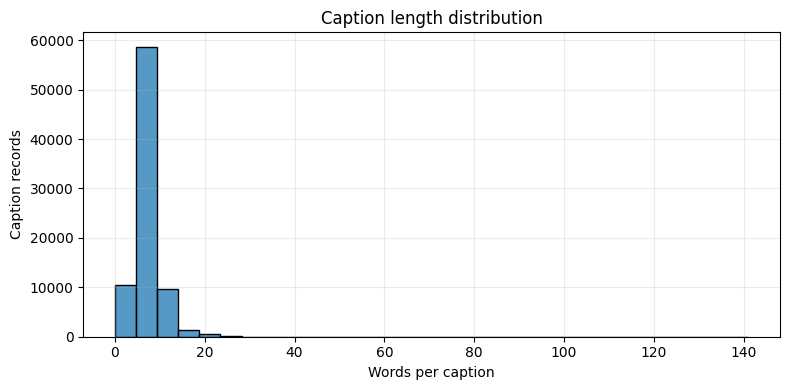

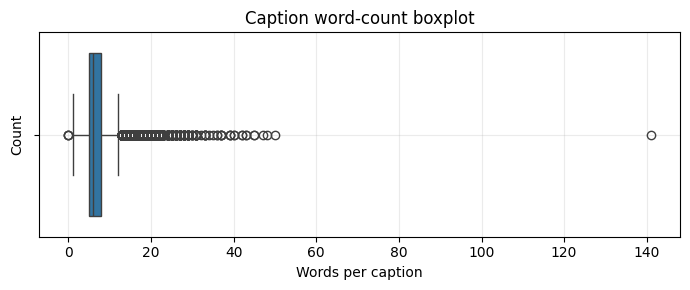

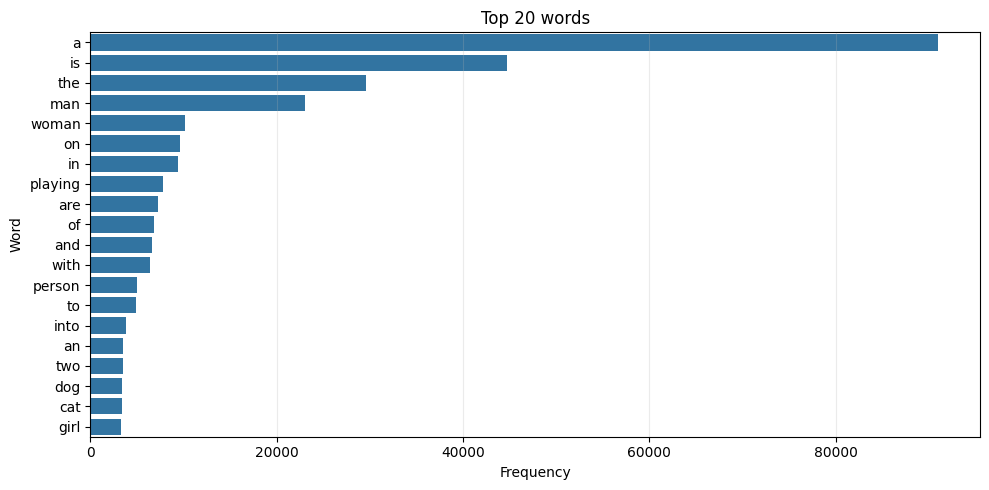

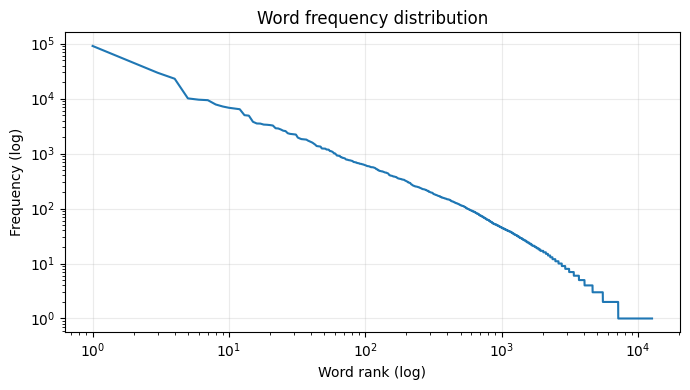

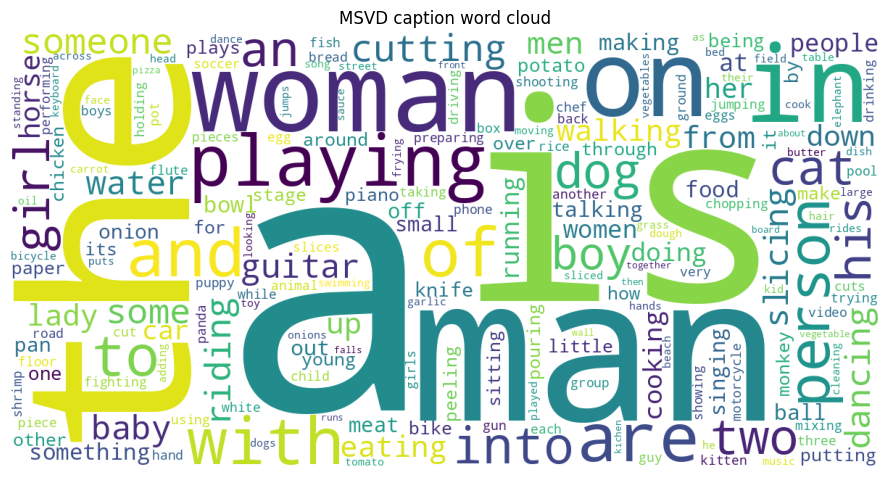

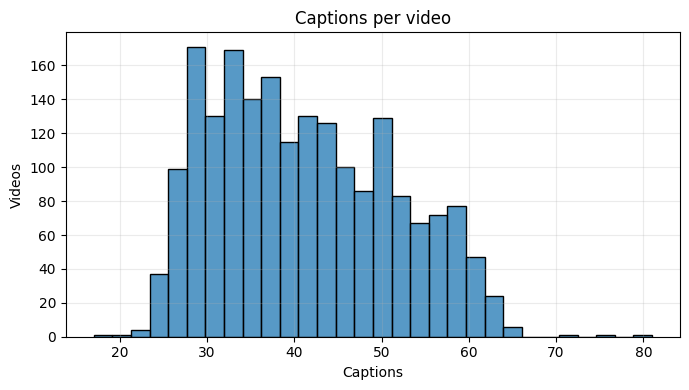

In [14]:
import re
from wordcloud import WordCloud
FIG = OUT / "results/figures"
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=220, bbox_inches="tight"); plt.show()
captions["word_count"] = captions.caption.str.findall(r"[A-Za-z']+").str.len()
words = [w.lower() for text in captions.caption for w in re.findall(r"[A-Za-z']+", text)]
freq = Counter(words)
fig, ax = plt.subplots(figsize=(8,4)); sns.histplot(captions.word_count, bins=30, ax=ax); ax.set(title="Caption length distribution", xlabel="Words per caption", ylabel="Caption records"); ax.grid(alpha=.25); savefig("caption_length_histogram.png")
fig, ax = plt.subplots(figsize=(7,3)); sns.boxplot(x=captions.word_count, ax=ax); ax.set(title="Caption word-count boxplot", xlabel="Words per caption", ylabel="Count"); ax.grid(alpha=.25); savefig("caption_wordcount_boxplot.png")
top = pd.DataFrame(freq.most_common(20), columns=["word","count"]); fig, ax = plt.subplots(figsize=(10,5)); sns.barplot(data=top, x="count", y="word", ax=ax); ax.set(title="Top 20 words", xlabel="Frequency", ylabel="Word"); ax.grid(axis="x", alpha=.25); savefig("top_words.png")
ranked = sorted(freq.values(), reverse=True); fig, ax = plt.subplots(figsize=(7,4)); ax.loglog(range(1,len(ranked)+1), ranked); ax.set(title="Word frequency distribution", xlabel="Word rank (log)", ylabel="Frequency (log)"); ax.grid(alpha=.25); savefig("word_frequency_distribution.png")
fig, ax = plt.subplots(figsize=(9,5)); ax.imshow(WordCloud(width=1200,height=600,background_color="white").generate_from_frequencies(freq)); ax.axis("off"); ax.set_title("MSVD caption word cloud"); savefig("wordcloud.png")
counts = captions.groupby("video_id").size(); fig, ax = plt.subplots(figsize=(7,4)); sns.histplot(counts, bins=30, ax=ax); ax.set(title="Captions per video", xlabel="Captions", ylabel="Videos"); ax.grid(alpha=.25); savefig("captions_per_video.png")


# 4. Dataset Splitting


In [15]:
def split_by_video_id(frame, train_ratio=.8, val_ratio=.1, test_ratio=.1, seed=42):
    if not np.isclose(train_ratio + val_ratio + test_ratio, 1): raise ValueError("Split ratios must sum to 1.")
    ids = np.array(sorted(frame.video_id.unique()))
    if len(ids) < 20: raise ValueError("At least 20 matched videos are needed for nonempty 80/10/10 splits.")
    train_ids, holdout = train_test_split(ids, test_size=val_ratio+test_ratio, random_state=seed, shuffle=True)
    val_ids, test_ids = train_test_split(holdout, test_size=test_ratio/(val_ratio+test_ratio), random_state=seed, shuffle=True)
    sets = {"train":set(train_ids), "validation":set(val_ids), "test":set(test_ids)}
    assert not (sets["train"] & sets["validation"] or sets["train"] & sets["test"] or sets["validation"] & sets["test"])
    return sets

# Only videos that can actually be evaluated enter the experiment split.
splits = split_by_video_id(available_captions, CFG.TRAIN_RATIO, CFG.VAL_RATIO, CFG.TEST_RATIO, CFG.SEED)
split_names = {"train":"train_video_ids.csv", "validation":"val_video_ids.csv", "test":"test_video_ids.csv"}
rows=[]
for name, ids in splits.items():
    pd.DataFrame({"video_id":sorted(ids)}).to_csv(OUT / split_names[name], index=False)
    rows.append({"Split":name, "Unique Videos":len(ids), "Caption Records":available_captions.video_id.isin(ids).sum()})
split_table=pd.DataFrame(rows); display(split_table)
split_metadata={k:sorted(v) for k,v in splits.items()}
with open(OUT / "configs/split_metadata.json", "w") as f: json.dump(split_metadata, f, indent=2)
print("Verified: train ∩ validation = train ∩ test = validation ∩ test = ∅")

,Split,Unique Videos,Caption Records
0,train,1576,64550
1,validation,197,7990
2,test,197,8298


Verified: train ∩ validation = train ∩ test = validation ∩ test = ∅


# 5. Video Preprocessing


Inspecting videos:   0%|          | 0/25 [00:00<?, ?it/s]

,video_id,path,readable,fps,frame_count,width,height,duration_s,error
0,-4wsuPCjDBc_5_15,/content/msvd/data/extracted/videos/-4wsuPCjDB...,True,29.917000,300,480,360,10.027743,
1,-7KMZQEsJW4_205_208,/content/msvd/data/extracted/videos/-7KMZQEsJW...,True,15.000000,46,320,240,3.066667,
2,-8y1Q0rA3n8_108_115,/content/msvd/data/extracted/videos/-8y1Q0rA3n...,True,29.970030,210,1280,720,7.007000,
3,-8y1Q0rA3n8_95_102,/content/msvd/data/extracted/videos/-8y1Q0rA3n...,True,29.970030,210,1280,720,7.007000,
4,-9CUm-2cui8_39_44,/content/msvd/data/extracted/videos/-9CUm-2cui...,True,29.916667,150,640,360,5.013928,


Unreadable videos logged: 0


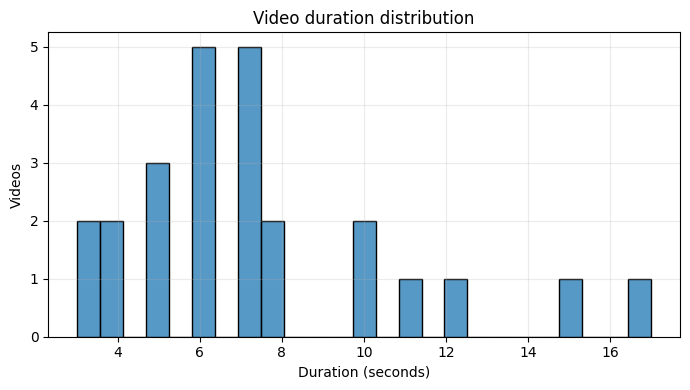

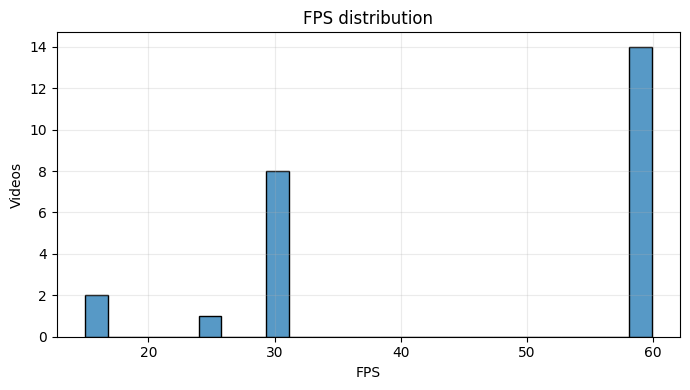

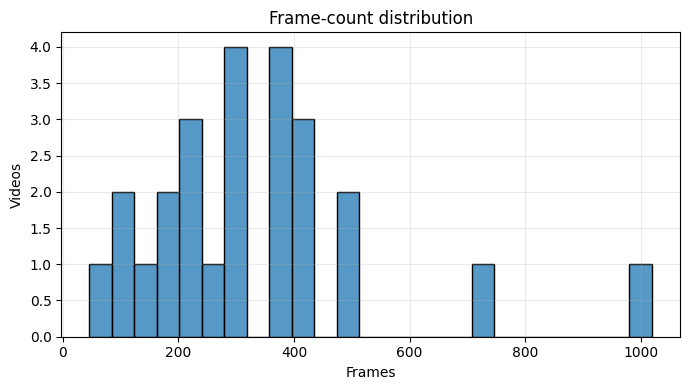

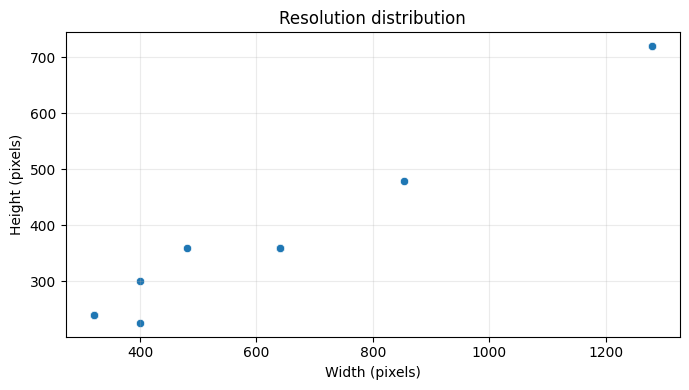

In [16]:
def inspect_video(video_path):
    cap=cv2.VideoCapture(str(video_path))
    try:
        if not cap.isOpened(): raise RuntimeError("OpenCV could not decode video")
        fps=float(cap.get(cv2.CAP_PROP_FPS)); n=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        if fps <= 0 or n <= 0: raise RuntimeError(f"invalid fps/frame_count ({fps}, {n})")
        return {"readable":True,"fps":fps,"frame_count":n,"width":w,"height":h,"duration_s":n/fps,"error":""}
    except Exception as exc: return {"readable":False,"fps":np.nan,"frame_count":np.nan,"width":np.nan,"height":np.nan,"duration_s":np.nan,"error":str(exc)}
    finally: cap.release()

def build_video_metadata(paths, run_all=False):
    iterable=list(paths.items()) if run_all else list(paths.items())[:min(25,len(paths))]
    records=[]
    for vid, path in tqdm(iterable, desc="Inspecting videos"):
        records.append({"video_id":vid,"path":str(path), **inspect_video(path)})
    meta=pd.DataFrame(records); meta.to_csv(OUT/"results/video_metadata.csv", index=False); return meta

video_metadata=build_video_metadata(video_paths, CFG.RUN_FULL_METADATA)
display(video_metadata.head()); print("Unreadable videos logged:", (~video_metadata.readable).sum())
if not video_metadata.empty:
    for col, title, xlab in [("duration_s","Video duration distribution","Duration (seconds)"),("fps","FPS distribution","FPS"),("frame_count","Frame-count distribution","Frames")]:
        fig,ax=plt.subplots(figsize=(7,4)); sns.histplot(video_metadata.loc[video_metadata.readable,col].dropna(), bins=25, ax=ax); ax.set(title=title,xlabel=xlab,ylabel="Videos"); ax.grid(alpha=.25); savefig(f"{col}_distribution.png")
    fig,ax=plt.subplots(figsize=(7,4)); sns.scatterplot(data=video_metadata[video_metadata.readable],x="width",y="height",ax=ax); ax.set(title="Resolution distribution",xlabel="Width (pixels)",ylabel="Height (pixels)"); ax.grid(alpha=.25); savefig("resolution_distribution.png")


# 6. Candidate Frame Extraction


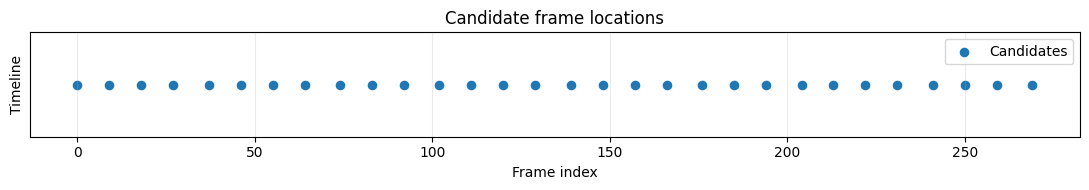

-rkErLY0rRc_26_35 30 candidate frames


In [17]:
def extract_candidate_frames(video_path, num_frames):
    """Decode only temporally-spaced candidates; returns RGB PIL frames, indices, timestamps."""
    cap=cv2.VideoCapture(str(video_path))
    if not cap.isOpened(): raise RuntimeError(f"Cannot open {video_path}")
    try:
        total=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); fps=float(cap.get(cv2.CAP_PROP_FPS))
        if total <= 0 or fps <= 0 or num_frames <= 0:
            raise ValueError(f"Invalid video metadata or candidate count: frames={total}, fps={fps}, candidates={num_frames}")
        indices=np.unique(np.linspace(0, total-1, min(num_frames,total), dtype=int))
        frames=[]; actual=[]
        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx)); ok, bgr=cap.read()
            if ok: frames.append(Image.fromarray(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))); actual.append(int(idx))
        return frames, actual, [i/fps for i in actual]
    finally: cap.release()

def cached_candidates(video_id):
    cache=OUT / "cache" / f"{video_id}_n{CFG.NUM_CANDIDATE_FRAMES}_s{CFG.IMAGE_SIZE}_candidates.npz"
    # Cache compact thumbnails, not thousands of source images.
    if cache.exists():
        z=np.load(cache, allow_pickle=False); return [Image.fromarray(x) for x in z["frames"]], z["indices"].tolist(), z["times"].tolist()
    frames,indices,times=extract_candidate_frames(video_paths[video_id], CFG.NUM_CANDIDATE_FRAMES)
    thumbs=np.stack([np.asarray(f.resize((CFG.IMAGE_SIZE,CFG.IMAGE_SIZE))) for f in frames])
    np.savez_compressed(cache,frames=thumbs,indices=np.array(indices),times=np.array(times))
    return [Image.fromarray(x) for x in thumbs],indices,times

def plot_timeline(indices, selected=None, title="Candidate frame locations"):
    fig,ax=plt.subplots(figsize=(11,2)); ax.scatter(indices,np.ones(len(indices)),label="Candidates",s=35)
    if selected is not None: ax.scatter(selected,np.ones(len(selected))*1.04,label="Selected",s=60,marker="*")
    ax.set(title=title,xlabel="Frame index",ylabel="Timeline"); ax.set_yticks([]); ax.grid(axis="x",alpha=.25); ax.legend(); savefig(title.lower().replace(" ","_")+".png")

sample_video_id=next(iter(sorted(splits["validation"] & set(video_paths))), None)
if sample_video_id:
    sample_frames,sample_indices,sample_times=cached_candidates(sample_video_id); plot_timeline(sample_indices, title="Candidate frame locations")
    print(sample_video_id, len(sample_frames), "candidate frames")

# 7. Baseline Frame Sampling


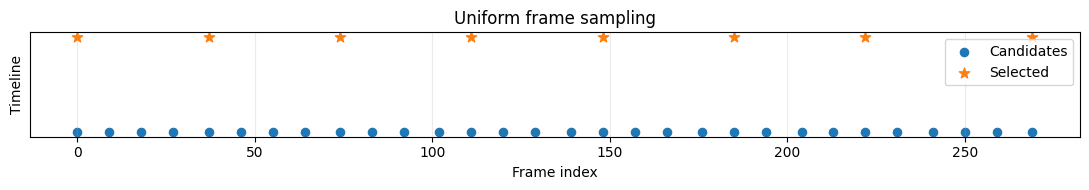

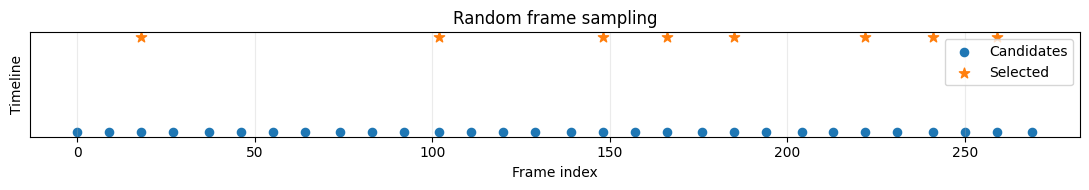

In [18]:
def uniform_selection(indices, k):
    return np.asarray(indices)[np.unique(np.linspace(0,len(indices)-1,min(k,len(indices)),dtype=int))].tolist()
def random_selection(indices, k, seed=42):
    rng=np.random.default_rng(seed); return sorted(rng.choice(np.asarray(indices),size=min(k,len(indices)),replace=False).tolist())
if sample_video_id:
    plot_timeline(sample_indices,uniform_selection(sample_indices,CFG.NUM_SELECTED_FRAMES),"Uniform frame sampling")
    plot_timeline(sample_indices,random_selection(sample_indices,CFG.NUM_SELECTED_FRAMES,CFG.SEED),"Random frame sampling")


# 8. Motion-Based Frame Selection


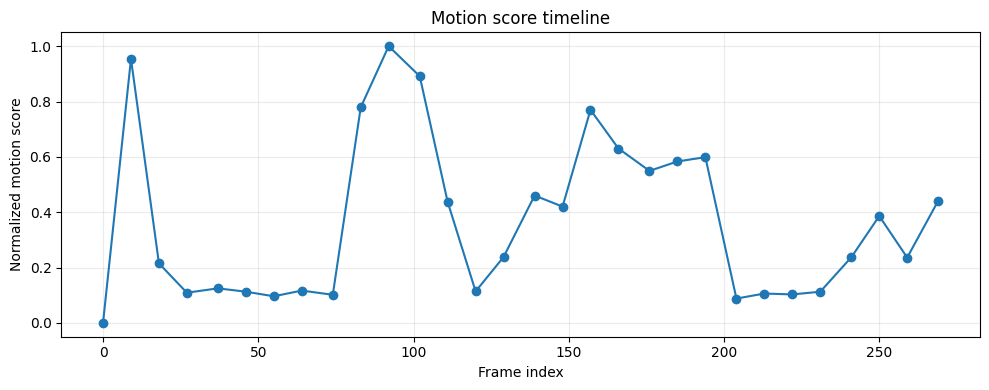

In [19]:
def minmax(scores):
    scores=np.asarray(scores,dtype=float)
    return np.zeros_like(scores) if len(scores)==0 or np.ptp(scores)<1e-12 else (scores-scores.min())/np.ptp(scores)

def motion_scores(frames):
    """Downsampled Farnebäck flow gives a T4-friendly candidate-level motion proxy."""
    if len(frames)==0: return np.array([])
    gray=[cv2.resize(cv2.cvtColor(np.asarray(f),cv2.COLOR_RGB2GRAY),(160,120)) for f in frames]
    score=[0.0]
    for prev,cur in zip(gray[:-1],gray[1:]):
        flow=cv2.calcOpticalFlowFarneback(prev,cur,None,.5,3,15,3,5,1.2,0)
        score.append(float(np.linalg.norm(flow,axis=2).mean()))
    return minmax(score)

if sample_video_id:
    sample_motion=motion_scores(sample_frames)
    pd.DataFrame({"video_id":sample_video_id,"frame_index":sample_indices,"timestamp":sample_times,"motion_score":sample_motion}).to_csv(OUT/"results/frame_scores/motion_scores.csv",index=False)
    fig,ax=plt.subplots(figsize=(10,4)); ax.plot(sample_indices,sample_motion,marker="o"); ax.set(title="Motion score timeline",xlabel="Frame index",ylabel="Normalized motion score"); ax.grid(alpha=.25); savefig("motion_score_timeline.png")


# 9. Semantic Frame Selection


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

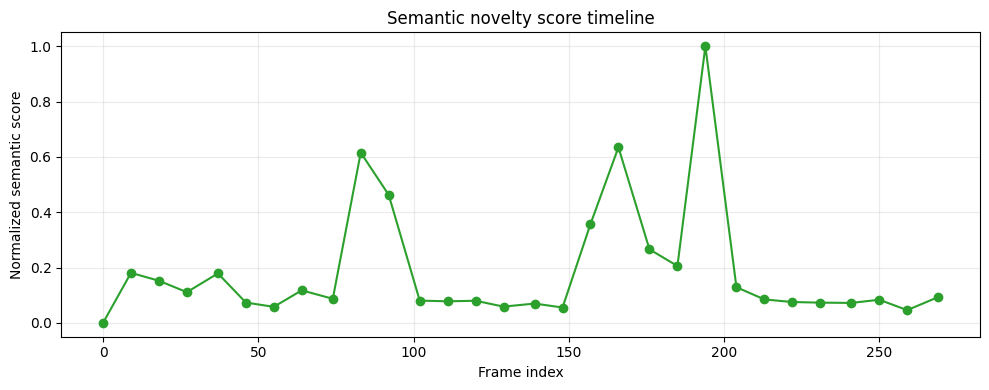

In [20]:
from transformers import AutoImageProcessor, AutoModel
semantic_processor=None; semantic_model=None
def load_semantic_encoder():
    global semantic_processor, semantic_model
    if semantic_model is None:
        name="facebook/dinov2-small"  # lightweight, caption-independent frozen vision encoder
        semantic_processor=AutoImageProcessor.from_pretrained(name)
        semantic_model=AutoModel.from_pretrained(name).to(device).eval()
    return semantic_processor,semantic_model

@torch.inference_mode()
def semantic_scores(frames, batch_size=16):
    if not frames: return np.array([]), np.empty((0,0))
    processor,model=load_semantic_encoder(); vectors=[]
    for start in range(0,len(frames),batch_size):
        inputs=processor(images=frames[start:start+batch_size],return_tensors="pt").to(device)
        emb=model(**inputs).last_hidden_state[:,0].float(); vectors.append(torch.nn.functional.normalize(emb,dim=-1).cpu())
    emb=torch.cat(vectors).numpy(); novelty=np.zeros(len(emb))
    if len(emb)>1: novelty[1:]=1-(emb[1:]*emb[:-1]).sum(axis=1)
    return minmax(novelty),emb

if sample_video_id:
    sample_semantic,sample_embeddings=semantic_scores(sample_frames)
    np.save(OUT/f"cache/{sample_video_id}_embeddings.npy",sample_embeddings)
    fig,ax=plt.subplots(figsize=(10,4)); ax.plot(sample_indices,sample_semantic,marker="o",color="tab:green"); ax.set(title="Semantic novelty score timeline",xlabel="Frame index",ylabel="Normalized semantic score"); ax.grid(alpha=.25); savefig("semantic_score_timeline.png")


# 10. Adaptive Semantic-Motion Keyframe Selection


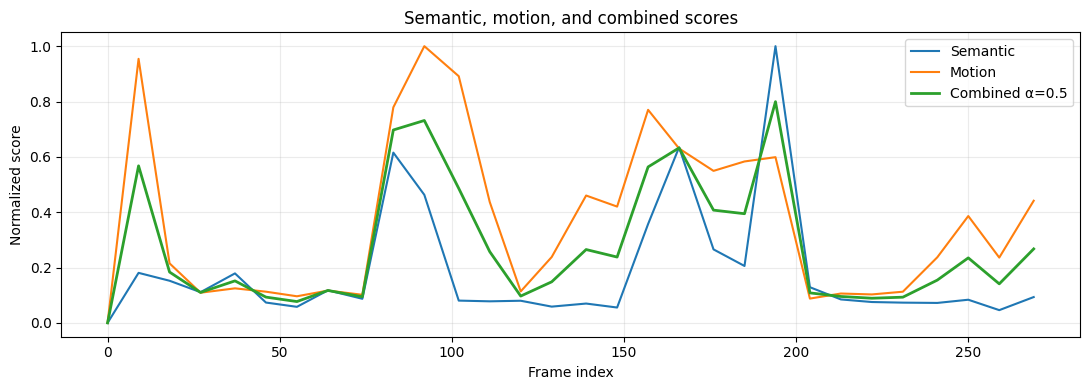

In [21]:
def fused_scores(semantic, motion, alpha): return alpha*minmax(semantic)+(1-alpha)*minmax(motion)
if sample_video_id:
    sample_combined=fused_scores(sample_semantic,sample_motion,CFG.ALPHA)
    fig,ax=plt.subplots(figsize=(11,4)); ax.plot(sample_indices,sample_semantic,label="Semantic"); ax.plot(sample_indices,sample_motion,label="Motion"); ax.plot(sample_indices,sample_combined,label=f"Combined α={CFG.ALPHA}",linewidth=2); ax.set(title="Semantic, motion, and combined scores",xlabel="Frame index",ylabel="Normalized score"); ax.grid(alpha=.25); ax.legend(); savefig("combined_score_timeline.png")


# 11. Temporal Diversity Filtering


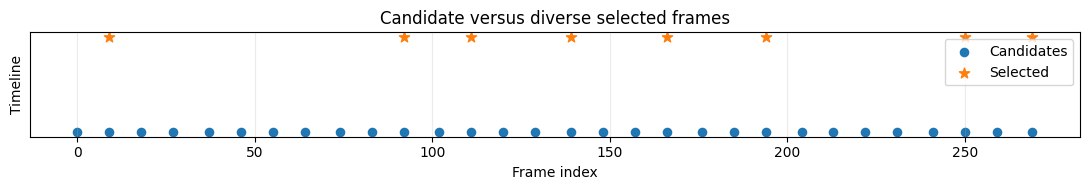

In [22]:
def select_diverse_keyframes(indices, scores, timestamps, k, min_temporal_distance):
    # Greedy temporal separation, followed by deterministic backfill for short clips.
    order=np.argsort(scores, kind="stable")[::-1]; chosen=[]
    for pos in order:
        if all(abs(timestamps[pos]-timestamps[q]) >= min_temporal_distance for q in chosen):
            chosen.append(int(pos))
        if len(chosen)==k: break
    for pos in order:
        if len(chosen)==k: break
        if int(pos) not in chosen: chosen.append(int(pos))
    chosen=sorted(chosen)
    return [indices[i] for i in chosen], [float(scores[i]) for i in chosen], [float(timestamps[i]) for i in chosen]

def select_from_candidates(frames, indices, times, method, k, alpha):
    if not frames: raise ValueError("No decodable candidate frames")
    if method=="uniform": selected=uniform_selection(indices,k); score=np.zeros(len(indices))
    elif method=="random": selected=random_selection(indices,k,CFG.SEED); score=np.zeros(len(indices))
    elif method=="motion": score=motion_scores(frames)
    elif method=="semantic": score,_=semantic_scores(frames)
    elif method in {"semantic_motion","semantic_motion_diverse"}:
        motion=motion_scores(frames); semantic,_=semantic_scores(frames)
        score=fused_scores(semantic,motion,alpha)
    else: raise ValueError(f"Unknown selection method: {method}")
    if method=="semantic_motion_diverse":
        selected,_,_=select_diverse_keyframes(indices,score,times,k,CFG.MIN_TEMPORAL_DISTANCE)
    elif method not in {"uniform","random"}:
        selected=sorted(np.asarray(indices)[np.argsort(score,kind="stable")[::-1][:min(k,len(indices))]].tolist())
    take=[indices.index(i) for i in selected]
    return [frames[i] for i in take], selected, [times[i] for i in take], score

def select_frames(video_id, method, k=None, alpha=None):
    k=CFG.NUM_SELECTED_FRAMES if k is None else k
    alpha=CFG.ALPHA if alpha is None else alpha
    if k <= 0 or not 0 <= alpha <= 1: raise ValueError("k must be positive and alpha must be in [0, 1]")
    frames,indices,times=cached_candidates(video_id)
    return select_from_candidates(frames,indices,times,method,k,alpha)

if sample_video_id:
    _,chosen,_,_=select_frames(sample_video_id,"semantic_motion_diverse")
    plot_timeline(sample_indices,chosen,"Candidate versus diverse selected frames")

# 12. BLIP-2 Model Setup


In [23]:
from transformers import Blip2Processor, Blip2ForConditionalGeneration

def make_contact_sheet(frames, image_size=224):
    """A deterministic visual storyboard lets one-image BLIP-2 consume all K selected frames."""
    if not frames: raise ValueError("No decoded frames")
    cols=math.ceil(math.sqrt(len(frames))); rows=math.ceil(len(frames)/cols)
    sheet=Image.new("RGB",(cols*image_size,rows*image_size),(0,0,0))
    for i,frame in enumerate(frames): sheet.paste(frame.convert("RGB").resize((image_size,image_size)),((i%cols)*image_size,(i//cols)*image_size))
    return sheet

class BLIP2VideoCaptioner:
    def __init__(self, config):
        self.cfg=config; self.processor=None; self.model=None; self.loaded_source=None
    def load_model(self):
        if self.model is not None and self.loaded_source==self.cfg.MODEL_NAME: return self
        self.model=None; self.processor=None
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        if device=="cuda": print(f"Loading {self.cfg.MODEL_NAME} in fp16; free GPU memory: {(torch.cuda.mem_get_info()[0]/2**30):.2f} GB")
        kwargs={"torch_dtype":torch.float16 if device=="cuda" else torch.float32}
        if self.cfg.USE_4BIT: kwargs.update(load_in_4bit=True, device_map="auto")
        self.processor=Blip2Processor.from_pretrained(self.cfg.MODEL_NAME)
        self.model=Blip2ForConditionalGeneration.from_pretrained(self.cfg.MODEL_NAME, **kwargs)
        if not self.cfg.USE_4BIT: self.model.to(device)
        self.model.eval(); self.loaded_source=self.cfg.MODEL_NAME; return self
    def prepare_frames(self, frames): return make_contact_sheet(frames,self.cfg.IMAGE_SIZE)
    @torch.inference_mode()
    def generate_caption(self, frames, prompt="A short video of"):
        sheet=self.prepare_frames(frames); inputs=self.processor(images=sheet,text=prompt,return_tensors="pt").to(device, torch.float16 if device=="cuda" else torch.float32)
        tokens=self.model.generate(**inputs,max_new_tokens=self.cfg.MAX_CAPTION_LENGTH,num_beams=3)
        return self.processor.batch_decode(tokens,skip_special_tokens=True)[0].strip()
    def generate_batch(self, frame_batches): return [self.generate_caption(x) for x in frame_batches]
    def save_checkpoint(self, path, extra=None):
        Path(path).mkdir(parents=True,exist_ok=True); self.model.save_pretrained(path); self.processor.save_pretrained(path); json.dump(extra or {},open(Path(path)/"metadata.json","w"),indent=2)
    def load_checkpoint(self,path):
        path=Path(path)
        if not path.exists(): raise FileNotFoundError(path)
        self.model=None; self.processor=None
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        is_adapter=(path/"adapter_config.json").exists()
        source=self.cfg.MODEL_NAME if is_adapter else str(path)
        self.processor=Blip2Processor.from_pretrained(source)
        base=Blip2ForConditionalGeneration.from_pretrained(
            source,torch_dtype=torch.float16 if device=="cuda" else torch.float32).to(device)
        if is_adapter:
            from peft import PeftModel
            self.model=PeftModel.from_pretrained(base,path).eval()
        else:
            self.model=base.eval()
        self.loaded_source=str(path)
        return self

captioner=BLIP2VideoCaptioner(CFG)
print("Configured model:",CFG.MODEL_NAME,"— download only when the next cell is run.")


Configured model: Salesforce/blip2-opt-2.7b — download only when the next cell is run.


# 13. Zero-Shot Baseline


In [24]:
def references_for(video_id): return captions.loc[captions.video_id.eq(video_id),"caption"].tolist()
def zero_shot_smoke_test(video_ids):
    captioner.load_model(); records=[]
    for vid in tqdm(list(video_ids)[:CFG.SMOKE_TEST_VIDEOS],desc="Zero-shot smoke test"):
        frames,indices,_,_=select_frames(vid,"uniform"); pred=captioner.generate_caption(frames)
        records.append({"video_id":vid,"sampling_method":"uniform","selected_frame_indices":json.dumps(indices),"caption":pred,"references":references_for(vid)})
    result=pd.DataFrame(records); display(result[["video_id","selected_frame_indices","caption","references"]]); return result

# Run only after paths are verified; this downloads BLIP-2 once.
# smoke_predictions = zero_shot_smoke_test(sorted(splits["validation"] & set(video_paths)))


# 14. BLIP-2 Fine-Tuning


In [25]:
from torch.utils.data import Dataset, DataLoader
from transformers import get_linear_schedule_with_warmup

class VideoCaptionDataset(Dataset):
    def __init__(self, ids, method, training=True):
        self.ids=[x for x in ids if x in video_paths]; self.method=method; self.training=training
    def __len__(self): return len(self.ids)
    def __getitem__(self,i):
        vid=self.ids[i]; frames,_,_,_=select_frames(vid,self.method)
        # A random ground-truth caption per video each epoch avoids duplicate-caption row sampling.
        refs=references_for(vid); caption=random.choice(refs) if self.training else refs[0]
        return vid, make_contact_sheet(frames,CFG.IMAGE_SIZE), caption

def collate_caption_batch(batch):
    vids,images,texts=zip(*batch); inputs=captioner.processor(images=list(images),text=list(texts),padding=True,return_tensors="pt")
    labels=inputs.input_ids.clone(); labels[labels==captioner.processor.tokenizer.pad_token_id]=-100; inputs["labels"]=labels
    return vids, {k:v.to(device) for k,v in inputs.items()}

def configure_lora(model):
    if not CFG.USE_LORA: return model
    from peft import LoraConfig, get_peft_model
    for p in model.parameters(): p.requires_grad=False
    config=LoraConfig(r=8,lora_alpha=16,lora_dropout=.05,target_modules=["q_proj","v_proj"],bias="none")
    model=get_peft_model(model,config); model.print_trainable_parameters(); return model

def gpu_memory_gb(): return torch.cuda.max_memory_allocated()/2**30 if torch.cuda.is_available() else 0.0
def train_one_epoch(model, loader, optimizer, scheduler, scaler):
    model.train(); running=0.; optimizer.zero_grad(set_to_none=True); start=time.perf_counter()
    for step,(_,batch) in enumerate(tqdm(loader,leave=False)):
        with torch.cuda.amp.autocast(enabled=device=="cuda"):
            loss=model(**batch).loss/CFG.GRADIENT_ACCUMULATION_STEPS
        scaler.scale(loss).backward()
        if (step+1)%CFG.GRADIENT_ACCUMULATION_STEPS==0 or step+1==len(loader):
            scaler.unscale_(optimizer); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True); scheduler.step()
        running += loss.item()*CFG.GRADIENT_ACCUMULATION_STEPS
    return running/max(1,len(loader)),time.perf_counter()-start

@torch.no_grad()
def validate(model,loader):
    model.eval(); losses=[]
    for _,batch in loader:
        with torch.cuda.amp.autocast(enabled=device=="cuda"): losses.append(model(**batch).loss.item())
    return float(np.mean(losses)) if losses else float("nan")

def save_checkpoint(model, directory, epoch, history):
    directory=Path(directory); directory.mkdir(parents=True,exist_ok=True); model.save_pretrained(directory/f"epoch_{epoch}"); json.dump(history,open(directory/"history.json","w"),indent=2)

# 15. Proposed Method Fine-Tuning


In [26]:
def run_finetuning(method, checkpoint_dir):
    """Same architecture/hyperparameters for uniform and adaptive control conditions."""
    # Reload the same pretrained weights for each comparison arm.
    captioner.model=None; captioner.processor=None
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    captioner.load_model(); model=configure_lora(captioner.model)
    captioner.loaded_source=f"finetuning:{method}"
    train_ids=sorted(splits["train"] & set(video_paths)); val_ids=sorted(splits["validation"] & set(video_paths))
    if CFG.MAX_TRAIN_VIDEOS: train_ids=train_ids[:CFG.MAX_TRAIN_VIDEOS]; val_ids=val_ids[:max(1,CFG.MAX_TRAIN_VIDEOS//8)]
    train_loader=DataLoader(VideoCaptionDataset(train_ids,method),batch_size=CFG.BATCH_SIZE,shuffle=True,num_workers=CFG.NUM_WORKERS,collate_fn=collate_caption_batch)
    val_loader=DataLoader(VideoCaptionDataset(val_ids,method,training=False),batch_size=CFG.BATCH_SIZE,num_workers=CFG.NUM_WORKERS,collate_fn=collate_caption_batch)
    opt=torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),lr=CFG.LEARNING_RATE)
    steps=math.ceil(len(train_loader)/CFG.GRADIENT_ACCUMULATION_STEPS)*CFG.NUM_EPOCHS; sched=get_linear_schedule_with_warmup(opt,max(1,int(.1*steps)),max(1,steps)); scaler=torch.cuda.amp.GradScaler(enabled=device=="cuda")
    hist=[]; best=float("inf"); patience=0
    for epoch in range(1,CFG.NUM_EPOCHS+1):
        tr,seconds=train_one_epoch(model,train_loader,opt,sched,scaler); va=validate(model,val_loader); row={"epoch":epoch,"train_loss":tr,"val_loss":va,"lr":sched.get_last_lr()[0],"epoch_time_s":seconds}; hist.append(row); print(row)
        if va<best: best=va; patience=0; save_checkpoint(model,checkpoint_dir,epoch,hist)
        else: patience+=1
        if patience>=2: print("Early stopping"); break
    pd.DataFrame(hist).to_csv(OUT/f"results/logs/{method}_training.csv",index=False)
    fig,ax=plt.subplots(figsize=(7,4)); pd.DataFrame(hist).plot(x="epoch",y=["train_loss","val_loss"],marker="o",ax=ax); ax.set(title=f"{method}: training and validation loss",xlabel="Epoch",ylabel="Loss"); ax.grid(alpha=.25); savefig(f"{method}_training_curve.png")
    return hist

# Controlled experiment: enable CFG.RUN_FINETUNING after the zero-shot smoke test.
if CFG.RUN_FINETUNING:
    uniform_history=run_finetuning("uniform",OUT/"checkpoints/uniform_baseline")
    proposed_history=run_finetuning("semantic_motion_diverse",OUT/"checkpoints/proposed")

# 16. Caption Generation


In [27]:
def generate_for_ids(video_ids, method, alpha=None, checkpoint=None, run_tag="manual"):
    if checkpoint: captioner.load_checkpoint(checkpoint)
    else: captioner.load_model()
    output=[]
    for vid in tqdm(list(video_ids),desc=f"Generate {method}"):
        begin=time.perf_counter()
        try:
            frames,indices,_,_=select_frames(vid,method,alpha=alpha)
            pred=captioner.generate_caption(frames)
            output.append({"video_id":vid,"sampling_method":method,"selected_frame_indices":json.dumps(indices),
                           "caption":pred,"error":None,"inference_time_s":time.perf_counter()-begin,
                           "gpu_memory_gb":gpu_memory_gb(),"frame_budget":CFG.NUM_SELECTED_FRAMES,
                           "alpha":CFG.ALPHA if alpha is None else alpha,"checkpoint":str(checkpoint or CFG.MODEL_NAME),"run_tag":run_tag})
        except Exception as exc:
            output.append({"video_id":vid,"sampling_method":method,"selected_frame_indices":None,
                           "caption":None,"error":str(exc),"inference_time_s":np.nan,
                           "gpu_memory_gb":np.nan,"frame_budget":CFG.NUM_SELECTED_FRAMES,
                           "alpha":CFG.ALPHA if alpha is None else alpha,"checkpoint":str(checkpoint or CFG.MODEL_NAME),"run_tag":run_tag})
    current=pd.DataFrame(output)
    safe_tag="".join(c if c.isalnum() or c in "-_" else "_" for c in run_tag)
    current.to_csv(OUT/f"results/generated_captions/{method}_{safe_tag}_k{CFG.NUM_SELECTED_FRAMES}_captions.csv",index=False)
    ledger_path=OUT/"results/generated_captions.csv"
    if ledger_path.exists():
        ledger=pd.read_csv(ledger_path)
        keys=["video_id","sampling_method","frame_budget","alpha","checkpoint","run_tag"]
        if all(k in ledger.columns for k in keys):
            ledger=ledger[~ledger.set_index(keys).index.isin(current.set_index(keys).index)]
            ledger=pd.concat([ledger,current],ignore_index=True)
        else:
            print("Existing caption ledger has an older schema; leaving it unchanged.")
            return current
    else: ledger=current
    ledger.to_csv(ledger_path,index=False)
    return current

# Example after freezing configuration:
# generated = generate_for_ids(sorted(splits["test"]), "semantic_motion_diverse", run_tag="test_final")

# 17. Automatic Evaluation


In [28]:
import nltk
for resource in ["wordnet","omw-1.4"]:
    try: nltk.data.find("corpora/"+resource)
    except LookupError: nltk.download(resource,quiet=True)
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer

METRIC_NAMES=["BLEU-1","BLEU-2","BLEU-3","BLEU-4","METEOR","ROUGE-L","CIDEr"]
def evaluate_captions(predictions, references):
    # One successful prediction per video. The caller supplies a common paired ID set.
    if predictions.empty or "caption" not in predictions:
        return {k:np.nan for k in METRIC_NAMES}
    if predictions.video_id.duplicated().any(): raise ValueError("Duplicate prediction video IDs")
    ok=predictions[predictions.caption.notna() & predictions.caption.astype(str).str.strip().ne("")]
    pairs=[(str(r.caption),references[r.video_id]) for r in ok.itertuples()
           if r.video_id in references and references[r.video_id]]
    if not pairs: return {k:np.nan for k in METRIC_NAMES}
    hyp=[p.split() for p,_ in pairs]; refs=[[x.split() for x in rs] for _,rs in pairs]
    smooth=SmoothingFunction().method1
    result={f"BLEU-{n}":corpus_bleu(refs,hyp,weights=tuple([1/n]*n),smoothing_function=smooth) for n in range(1,5)}
    result["METEOR"]=float(np.mean([meteor_score([x.split() for x in rs],p.split()) for p,rs in pairs]))
    rouge=rouge_scorer.RougeScorer(["rougeL"],use_stemmer=True)
    result["ROUGE-L"]=float(np.mean([max(rouge.score(x,p)["rougeL"].fmeasure for x in rs) for p,rs in pairs]))
    result["CIDEr"]=np.nan
    try:
        from pycocoevalcap.cider.cider import Cider
        gts={str(i):rs for i,(_,rs) in enumerate(pairs)}
        res={str(i):[p] for i,(p,_) in enumerate(pairs)}
        result["CIDEr"]=Cider().compute_score(gts,res)[0]
    except ImportError:
        print("CIDEr unavailable: install pycocoevalcap to report it.")
    return result

def paired_success_ids(prediction_tables, requested_ids):
    common=set(requested_ids)
    for table in prediction_tables.values():
        valid=table[table.caption.notna() & table.caption.astype(str).str.strip().ne("")]
        common &= set(valid.video_id)
    return sorted(common)

test_references={vid:references_for(vid) for vid in splits["test"]}

# 17b. Validation-Only Alpha Selection and Test Freeze

In [29]:
def plot_alpha_sensitivity(validation_ids, alphas=(0,.25,.5,.75,1.0)):
    validation_ids=sorted(set(validation_ids) & splits["validation"])
    if not validation_ids: raise ValueError("No validation videos available")
    rows=[]; predictions={}
    refs={v:references_for(v) for v in validation_ids}
    for alpha in alphas:
        preds=generate_for_ids(validation_ids,"semantic_motion_diverse",alpha=alpha,
                               run_tag=f"validation_alpha_{alpha:g}")
        predictions[alpha]=preds
    paired_ids=paired_success_ids(predictions,validation_ids)
    print(f"Paired validation videos across all alpha values: {len(paired_ids)}/{len(validation_ids)}")
    for alpha,preds in predictions.items():
        paired=preds[preds.video_id.isin(paired_ids)]
        rows.append({"alpha":alpha,"Requested Videos":len(validation_ids),
                     "Successful Videos":int(preds.caption.notna().sum()),"Paired Videos":len(paired_ids),
                     **evaluate_captions(paired,refs)})
    df=pd.DataFrame(rows); df.to_csv(OUT/"results/metrics/alpha_validation.csv",index=False)
    for metric in ["CIDEr","BLEU-4"]:
        if df[metric].notna().any():
            fig,ax=plt.subplots(figsize=(6,4)); sns.lineplot(data=df,x="alpha",y=metric,marker="o",ax=ax)
            ax.set(title=f"Alpha sensitivity ({metric}, validation only)",xlabel="Semantic weight α",ylabel=metric)
            ax.grid(alpha=.25); savefig(f"alpha_vs_{metric.lower().replace('-','_')}.png")
    return df

def freeze_test_configuration(validation_results=None, primary="CIDEr", fallback="BLEU-4"):
    if validation_results is None:
        chosen=CFG.ALPHA; metric="prespecified"
    else:
        metric=primary if validation_results[primary].notna().any() else fallback
        if not validation_results[metric].notna().any(): raise ValueError("No valid validation metric")
        chosen=float(validation_results.loc[validation_results[metric].idxmax(),"alpha"])
    CFG.ALPHA=chosen
    record={"config":asdict(CFG),"selection_metric":metric,
            "validation_results":"results/metrics/alpha_validation.csv" if validation_results is not None else None}
    with open(OUT/"configs/frozen_test_config.json","w") as f: json.dump(record,f,indent=2)
    print(f"Frozen alpha={chosen:g} using {metric}; test evaluation may now run.")
    return record

def assert_test_configuration_frozen():
    path=OUT/"configs/frozen_test_config.json"
    if not path.exists(): raise RuntimeError("Freeze alpha on validation (or prespecify it) before test evaluation.")
    frozen=json.loads(path.read_text())["config"]
    fields=["SEED","NUM_CANDIDATE_FRAMES","NUM_SELECTED_FRAMES","ALPHA","MIN_TEMPORAL_DISTANCE","MODEL_NAME"]
    changed=[field for field in fields if field != "NUM_SELECTED_FRAMES" and frozen[field] != getattr(CFG,field)]
    if changed: raise RuntimeError(f"Test configuration changed after freeze: {changed}")

# Run one of these BEFORE enabling test ablations or the frame-budget study:
# alpha_validation = plot_alpha_sensitivity(sorted(splits["validation"]))
# freeze_test_configuration(alpha_validation)
# freeze_test_configuration()  # use the prespecified CFG.ALPHA without tuning

# 18. Ablation Study


In [30]:
METHODS=["uniform","random","motion","semantic","semantic_motion","semantic_motion_diverse"]
def run_ablation(ids, methods=METHODS):
    assert_test_configuration_frozen()
    ids=sorted(set(ids) & splits["test"])
    predictions={}
    for method in methods:
        if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
        predictions[method]=generate_for_ids(ids,method,run_tag="test_ablation")
    paired_ids=paired_success_ids(predictions,ids)
    print(f"Paired test videos: {len(paired_ids)}/{len(ids)}. Failures remain in saved prediction tables.")
    rows=[]
    for method,preds in predictions.items():
        paired=preds[preds.video_id.isin(paired_ids)]
        metric=evaluate_captions(paired,test_references)
        rows.append({"Method":method,"Frames":CFG.NUM_SELECTED_FRAMES,"Requested Videos":len(ids),
                     "Successful Videos":int(preds.caption.notna().sum()),"Paired Videos":len(paired_ids),
                     **metric,"Inference Time":paired.inference_time_s.mean(),
                     "GPU Memory":paired.gpu_memory_gb.max()})
    table=pd.DataFrame(rows)
    table.to_csv(OUT/"results/metrics/ablation_metrics.csv",index=False)
    table.to_csv(OUT/"results/metrics.csv",index=False)
    return table
if CFG.RUN_TEST_ABLATIONS:
    ablation=run_ablation(sorted(splits["test"])); display(ablation)
    fig,ax=plt.subplots(figsize=(10,4)); sns.barplot(data=ablation,x="Method",y="BLEU-4",ax=ax)
    ax.tick_params(axis="x",rotation=30); ax.set(title="Ablation comparison",xlabel="Method",ylabel="BLEU-4")
    ax.grid(axis="y",alpha=.25); savefig("ablation_comparison.png")

# 19. Frame Budget Study


In [31]:
def frame_budget_study(ids, budgets=(4,8,12,16)):
    assert_test_configuration_frozen()
    ids=sorted(set(ids) & splits["test"])
    original_budget=CFG.NUM_SELECTED_FRAMES
    predictions={}
    try:
        for k in budgets:
            CFG.NUM_SELECTED_FRAMES=k
            for method in ["uniform","semantic_motion_diverse"]:
                if torch.cuda.is_available(): torch.cuda.reset_peak_memory_stats()
                predictions[(k,method)]=generate_for_ids(ids,method,run_tag=f"test_budget_{k}")
    finally: CFG.NUM_SELECTED_FRAMES=original_budget
    paired_ids=paired_success_ids(predictions,ids)
    print(f"Paired test videos across all budgets: {len(paired_ids)}/{len(ids)}")
    records=[]
    for (k,method),preds in predictions.items():
        paired=preds[preds.video_id.isin(paired_ids)]
        metrics=evaluate_captions(paired,test_references)
        records.append({"Method":method,"Frames":k,"Requested Videos":len(ids),
                        "Successful Videos":int(preds.caption.notna().sum()),"Paired Videos":len(paired_ids),
                        **metrics,"Inference Time":paired.inference_time_s.mean(),
                        "GPU Memory":paired.gpu_memory_gb.max()})
    df=pd.DataFrame(records); df.to_csv(OUT/"results/metrics/frame_budget.csv",index=False)
    return df
if CFG.RUN_FRAME_BUDGET_STUDY:
    budget_results=frame_budget_study(sorted(splits["test"]))
    for y,title in [("CIDEr","Frame count versus CIDEr"),("Inference Time","Frame count versus inference time"),("GPU Memory","Frame count versus GPU memory")]:
        if budget_results[y].notna().any():
            fig,ax=plt.subplots(figsize=(7,4)); sns.lineplot(data=budget_results,x="Frames",y=y,hue="Method",marker="o",ax=ax)
            ax.set(title=title,xlabel="Selected frames",ylabel=y); ax.grid(alpha=.25)
            savefig(title.lower().replace(" ","_")+".png")

# 20. Efficiency Analysis

In [32]:
def efficiency_row(video_id, method):
    # Cold decode plus method-specific scoring and one BLIP-2 call per video.
    start=time.perf_counter()
    frames,indices,times=extract_candidate_frames(video_paths[video_id],CFG.NUM_CANDIDATE_FRAMES)
    extraction=time.perf_counter()-start
    start=time.perf_counter()
    selected,_,_,_=select_from_candidates(frames,indices,times,method,CFG.NUM_SELECTED_FRAMES,CFG.ALPHA)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    selection=time.perf_counter()-start
    if torch.cuda.is_available(): torch.cuda.synchronize()
    start=time.perf_counter()
    _=captioner.generate_caption(selected)
    if torch.cuda.is_available(): torch.cuda.synchronize()
    caption_time=time.perf_counter()-start
    return {"Method":method,"Candidate Frames":len(frames),"Frames":len(selected),
            "Frame Reduction":1-len(selected)/len(frames),"Frame Extraction Time":extraction,
            "Selection Time":selection,"BLIP-2 Inference Time":caption_time,
            "Total Inference Time":extraction+selection+caption_time,"GPU Memory":gpu_memory_gb()}

def plot_efficiency(efficiency):
    fig,ax=plt.subplots(figsize=(7,4))
    sns.barplot(data=efficiency,x="Method",y="Total Inference Time",ax=ax)
    ax.set(title="End-to-end runtime per video",xlabel="Method",ylabel="Seconds")
    ax.grid(axis="y",alpha=.25); savefig("end_to_end_runtime_comparison.png")
    return efficiency

# Captioner loading is excluded from timing; use multiple test videos for a representative estimate.
# captioner.load_model()
# efficiency = pd.DataFrame([efficiency_row(v,m) for v in sorted(splits["test"])[:10]
#                            for m in ["uniform","semantic_motion_diverse"]])
# efficiency.to_csv(OUT/"results/metrics/efficiency.csv",index=False)
# display(plot_efficiency(efficiency))

### Interpreting runtime and frame reduction

All methods use the same selected-frame budget and make **one BLIP-2 call per video** on a contact sheet. Frame reduction is therefore equal across methods at a fixed budget. Semantic scoring adds DINOv2 work and may make the proposed method slower; the research question is whether caption quality improves enough to justify that cost. Use measured end-to-end time and paired caption metrics for the tradeoff. Repeat timings after model warm-up and report hardware, video count, and variability before claiming an efficiency gain.


# 21. Qualitative Analysis


In [33]:
def qualitative_analysis(test_ids, n=5):
    ids=np.random.default_rng(CFG.SEED).choice(sorted(test_ids),size=min(n,len(test_ids)),replace=False)
    captioner.load_model(); records=[]
    for vid in ids:
        uni,ui,_,_=select_frames(vid,"uniform"); prop,pi,_,_=select_frames(vid,"semantic_motion_diverse")
        fig,axes=plt.subplots(2,max(len(uni),len(prop)),figsize=(16,4))
        for row,fs,title in zip(axes,[uni,prop],["Uniform","Adaptive semantic-motion"]):
            for ax,fr in zip(row,fs): ax.imshow(fr); ax.axis("off")
            row[0].set_ylabel(title,fontsize=11)
        fig.suptitle(f"{vid} | References: {' | '.join(references_for(vid)[:2])}",fontsize=10); plt.tight_layout(); plt.savefig(OUT/f"results/qualitative/{vid}.png",dpi=180); plt.show()
        records.append({"video_id":vid,"references":references_for(vid),"uniform_caption":captioner.generate_caption(uni),"proposed_caption":captioner.generate_caption(prop),"uniform_indices":ui,"proposed_indices":pi})
    return pd.DataFrame(records)
# qualitative = qualitative_analysis(splits["test"] & set(video_paths))


# 22. Final Research Results

In [34]:
def final_results_table(ablation_table=None, budget_table=None):
    frames=[x for x in [ablation_table,budget_table] if x is not None]
    if not frames: return pd.DataFrame(columns=["Method","Frame Count","BLEU-1","BLEU-2","BLEU-3","BLEU-4","METEOR","ROUGE-L","CIDEr","Inference Time","GPU Memory","Frame Reduction"])
    result=pd.concat(frames,ignore_index=True).rename(columns={"Frames":"Frame Count"})
    wanted=["Method","Frame Count","BLEU-1","BLEU-2","BLEU-3","BLEU-4","METEOR","ROUGE-L","CIDEr","Inference Time","GPU Memory","Frame Reduction"]
    result=result.reindex(columns=[c for c in wanted if c in result.columns]); result.to_csv(OUT/"results/final_results.csv",index=False); return result
final_results=final_results_table(globals().get("ablation"),globals().get("budget_results")); display(final_results)


,Method,Frame Count,BLEU-1,BLEU-2,BLEU-3,BLEU-4,METEOR,ROUGE-L,CIDEr,Inference Time,GPU Memory,Frame Reduction


# 23. Save Artifacts

In [35]:
# Config/splits/metadata, metrics, figures, generated captions, score files, qualitative figures,
# logs, checkpoints, and final_results.csv are written under OUT. Record final config after tuning.
with open(OUT/"configs/final_runtime_config.json","w") as f: json.dump(asdict(CFG),f,indent=2)
print("Artifacts saved under:",OUT)
for folder in ["results/figures","results/metrics","results/generated_captions","results/frame_scores","results/qualitative","results/logs","checkpoints/uniform_baseline","checkpoints/proposed","configs"]:
    print(" -",OUT/folder)


Artifacts saved under: /content/video_captioning_outputs
 - /content/video_captioning_outputs/results/figures
 - /content/video_captioning_outputs/results/metrics
 - /content/video_captioning_outputs/results/generated_captions
 - /content/video_captioning_outputs/results/frame_scores
 - /content/video_captioning_outputs/results/qualitative
 - /content/video_captioning_outputs/results/logs
 - /content/video_captioning_outputs/checkpoints/uniform_baseline
 - /content/video_captioning_outputs/checkpoints/proposed
 - /content/video_captioning_outputs/configs


In [39]:
from pathlib import Path
from dataclasses import asdict, is_dataclass
import datetime as dt
import hashlib
import json
import shutil

OUT = Path(OUT)
OUT.mkdir(parents=True, exist_ok=True)

expected_directories = [
    "results/figures",
    "results/metrics",
    "results/generated_captions",
    "results/frame_scores",
    "results/qualitative",
    "results/logs",
    "checkpoints/uniform_baseline",
    "checkpoints/proposed",
    "configs",
    "exports",
]

for relative_directory in expected_directories:
    (OUT / relative_directory).mkdir(
        parents=True,
        exist_ok=True,
    )

# Save the final runtime configuration.
if is_dataclass(CFG):
    final_config = asdict(CFG)
elif hasattr(CFG, "__dict__"):
    final_config = vars(CFG)
else:
    final_config = dict(CFG)

config_path = OUT / "configs/final_runtime_config.json"
config_path.write_text(
    json.dumps(
        final_config,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()

    with path.open("rb") as handle:
        for chunk in iter(
            lambda: handle.read(8 * 1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


# Build a reproducibility manifest before creating the ZIP.
artifact_files = sorted(
    path
    for path in OUT.rglob("*")
    if path.is_file()
    and "exports" not in path.relative_to(OUT).parts
)

manifest = {
    "created_at_utc": dt.datetime.now(
        dt.timezone.utc
    ).isoformat(),
    "artifact_root": str(OUT),
    "run_id": globals().get("RUN_ID"),
    "run_mode": globals().get("MODE"),
    "file_count": len(artifact_files),
    "total_bytes": int(sum(
        path.stat().st_size
        for path in artifact_files
    )),
    "files": [
        {
            "path": str(path.relative_to(OUT)),
            "bytes": path.stat().st_size,
            "sha256": file_sha256(path),
        }
        for path in artifact_files
    ],
}

manifest_path = OUT / "configs/artifact_manifest.json"
manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

timestamp = dt.datetime.now(
    dt.timezone.utc
).strftime("%Y%m%dT%H%M%SZ")

temporary_archive_base = (
    OUT.parent
    / f"{OUT.name}_{timestamp}"
)

temporary_zip = Path(
    shutil.make_archive(
        str(temporary_archive_base),
        "zip",
        root_dir=OUT,
    )
)

final_zip = (
    OUT
    / "exports"
    / f"video_captioning_research_artifacts_{timestamp}.zip"
)

shutil.move(
    str(temporary_zip),
    str(final_zip),
)

print(f"Artifact root: {OUT}")
print(f"Files included: {manifest['file_count']:,}")
print(
    f"Uncompressed size: "
    f"{manifest['total_bytes'] / 2**20:.2f} MiB"
)
print(
    f"ZIP size: {final_zip.stat().st_size / 2**20:.2f} MiB"
)
print(f"Manifest: {manifest_path}")
print(f"Downloadable ZIP: {final_zip}")

# Set to True only when you are ready for the browser download.
DOWNLOAD_NOW = False

if DOWNLOAD_NOW:
    from google.colab import files
    files.download(str(final_zip))
else:
    print(
        "Set DOWNLOAD_NOW=True and rerun this cell to download the ZIP."
    )

Artifact root: /content/video_captioning_outputs
Files included: 32
Uncompressed size: 4.18 MiB
ZIP size: 3.98 MiB
Manifest: /content/video_captioning_outputs/configs/artifact_manifest.json
Downloadable ZIP: /content/video_captioning_outputs/exports/video_captioning_research_artifacts_20260927T135835Z.zip
Set DOWNLOAD_NOW=True and rerun this cell to download the ZIP.


In [42]:
from pathlib import Path
import pandas as pd
from IPython.display import display

OUT = Path("/content/video_captioning_outputs")

figure_directories = [
    OUT / "results/figures",
    OUT / "results/qualitative",
]

supported_extensions = {
    ".png",
    ".jpg",
    ".jpeg",
    ".svg",
    ".pdf",
}

graph_files = sorted({
    path
    for directory in figure_directories
    if directory.exists()
    for path in directory.rglob("*")
    if path.is_file()
    and path.suffix.lower() in supported_extensions
})

graph_inventory = pd.DataFrame([
    {
        "number": index,
        "filename": path.name,
        "type": path.suffix.lower(),
        "size_kb": round(path.stat().st_size / 1024, 2),
        "relative_path": str(path.relative_to(OUT)),
        "absolute_path": str(path),
    }
    for index, path in enumerate(graph_files, start=1)
])

if graph_inventory.empty:
    print(
        "No saved graphs were found. Expected them under:\n"
        f"  {OUT / 'results/figures'}\n"
        f"  {OUT / 'results/qualitative'}"
    )
else:
    print(f"Found {len(graph_files)} saved graph/figure files.")
    display(graph_inventory)

Found 17 saved graph/figure files.


,number,filename,type,size_kb,relative_path,absolute_path
0,1,candidate_frame_locations.png,.png,33.32,results/figures/candidate_frame_locations.png,/content/video_captioning_outputs/results/figu...
1,2,candidate_versus_diverse_selected_frames.png,.png,42.63,results/figures/candidate_versus_diverse_selec...,/content/video_captioning_outputs/results/figu...
2,3,caption_length_histogram.png,.png,57.29,results/figures/caption_length_histogram.png,/content/video_captioning_outputs/results/figu...
3,4,caption_wordcount_boxplot.png,.png,36.41,results/figures/caption_wordcount_boxplot.png,/content/video_captioning_outputs/results/figu...
4,5,captions_per_video.png,.png,46.21,results/figures/captions_per_video.png,/content/video_captioning_outputs/results/figu...
5,6,combined_score_timeline.png,.png,196.59,results/figures/combined_score_timeline.png,/content/video_captioning_outputs/results/figu...
6,7,duration_s_distribution.png,.png,36.42,results/figures/duration_s_distribution.png,/content/video_captioning_outputs/results/figu...
7,8,fps_distribution.png,.png,30.72,results/figures/fps_distribution.png,/content/video_captioning_outputs/results/figu...
8,9,frame_count_distribution.png,.png,41.42,results/figures/frame_count_distribution.png,/content/video_captioning_outputs/results/figu...
9,10,motion_score_timeline.png,.png,103.56,results/figures/motion_score_timeline.png,/content/video_captioning_outputs/results/figu...


### 1. Candidate Frame Locations
`results/figures/candidate_frame_locations.png`

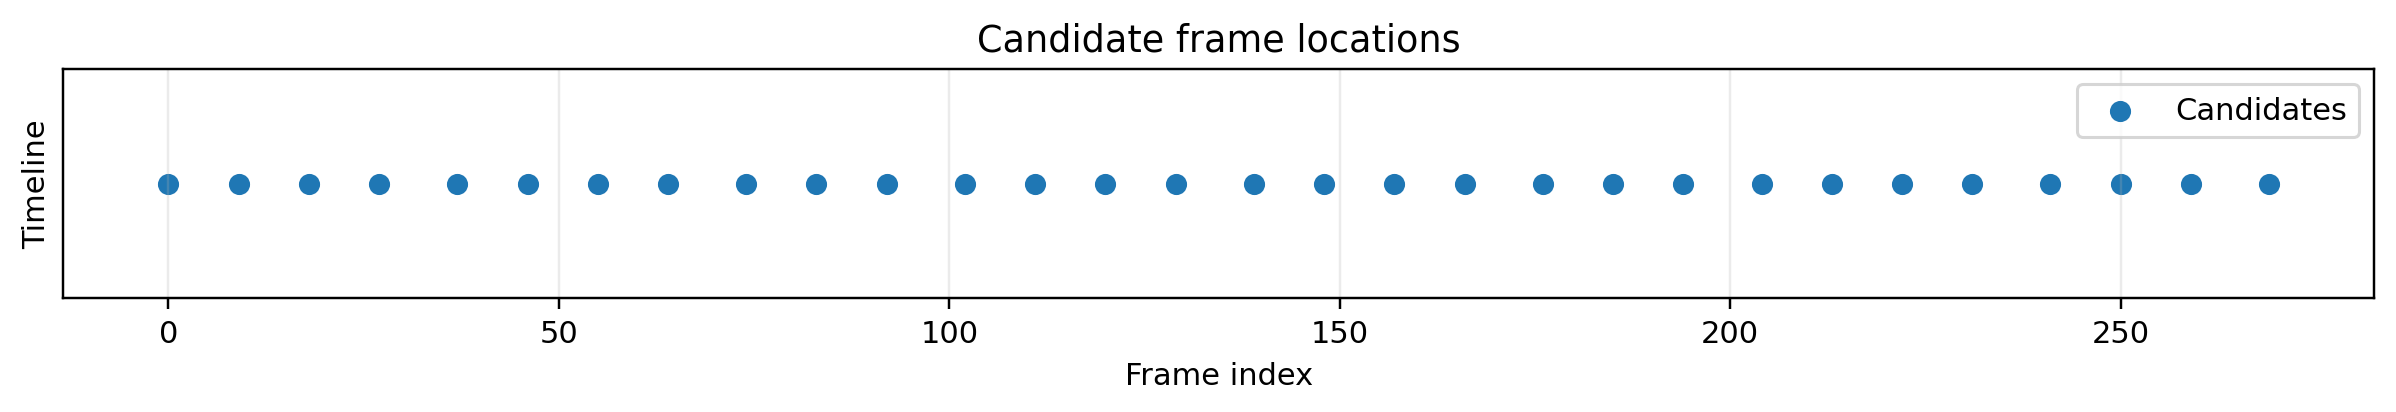

---

### 2. Candidate Versus Diverse Selected Frames
`results/figures/candidate_versus_diverse_selected_frames.png`

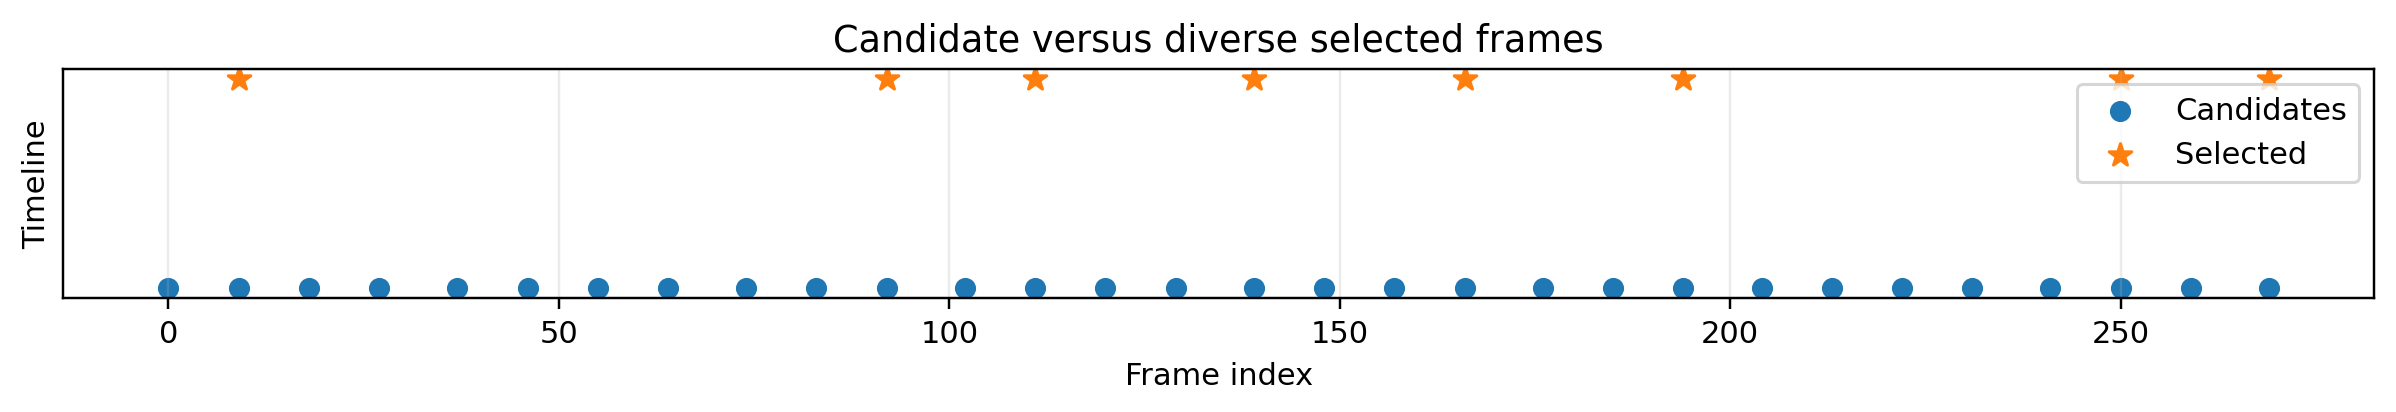

---

### 3. Caption Length Histogram
`results/figures/caption_length_histogram.png`

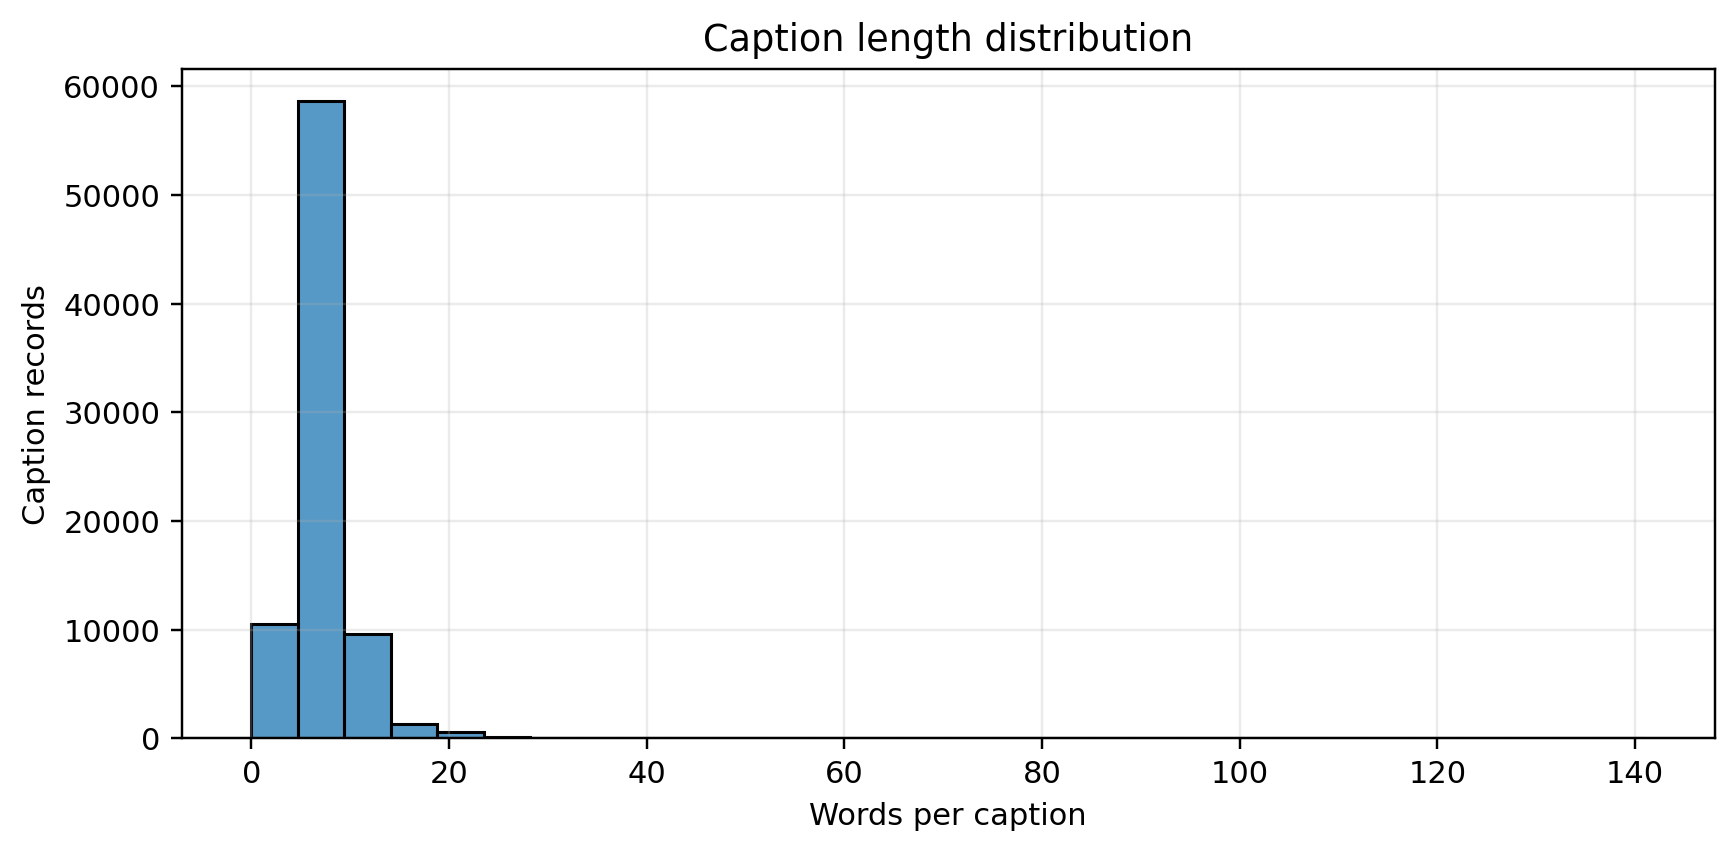

---

### 4. Caption Wordcount Boxplot
`results/figures/caption_wordcount_boxplot.png`

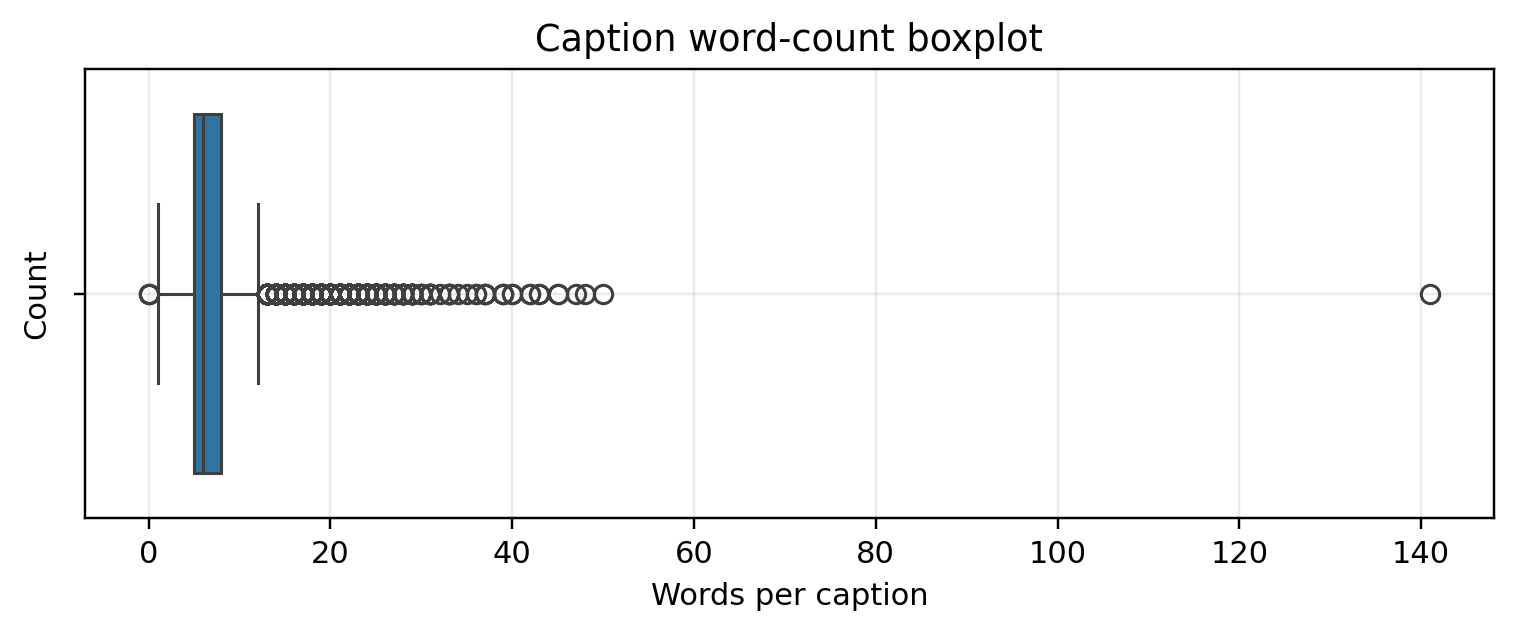

---

### 5. Captions Per Video
`results/figures/captions_per_video.png`

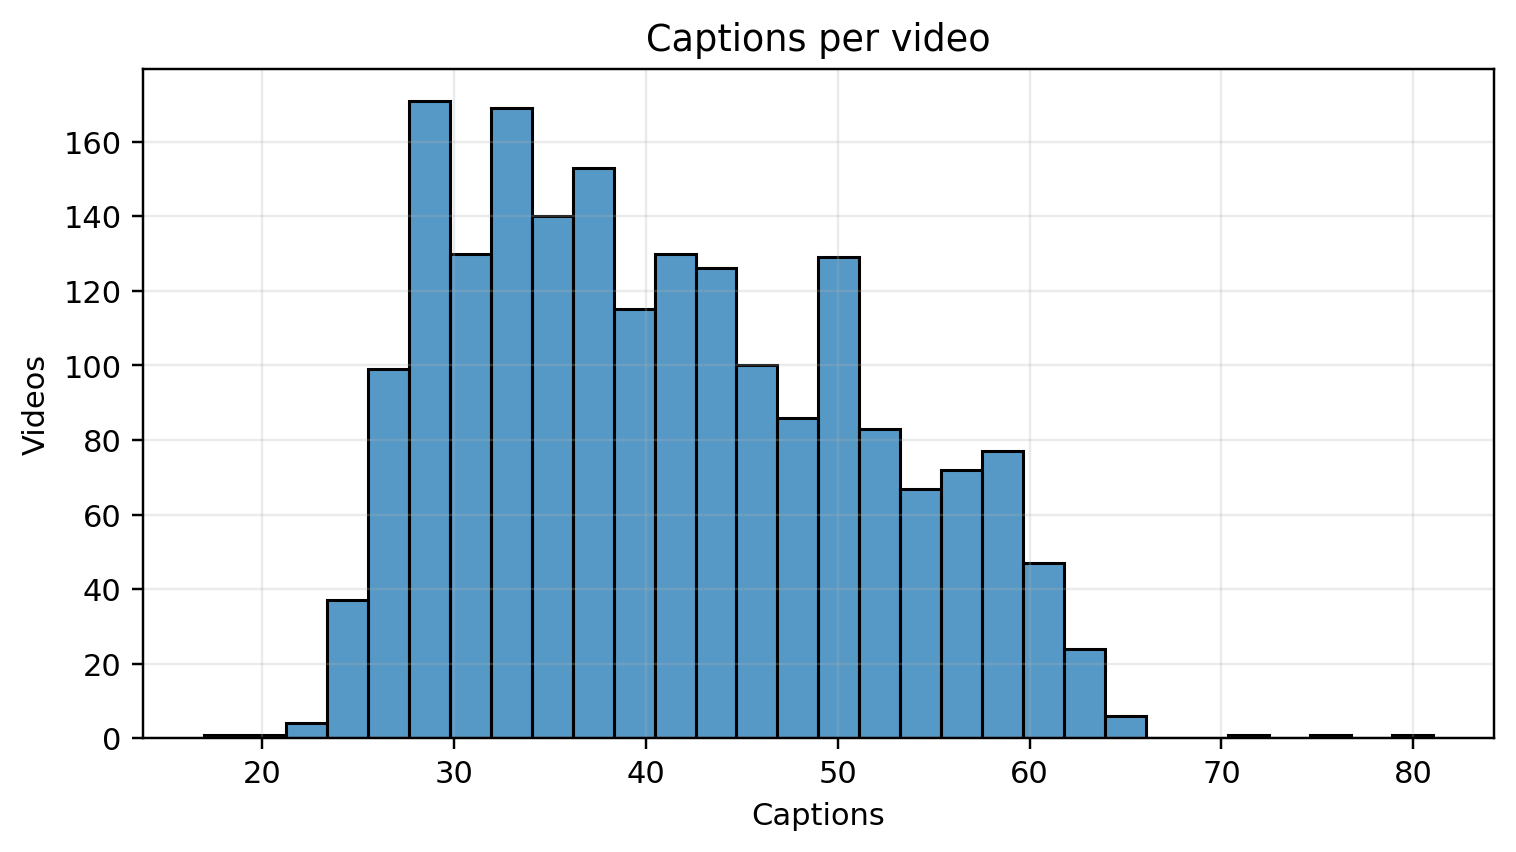

---

### 6. Combined Score Timeline
`results/figures/combined_score_timeline.png`

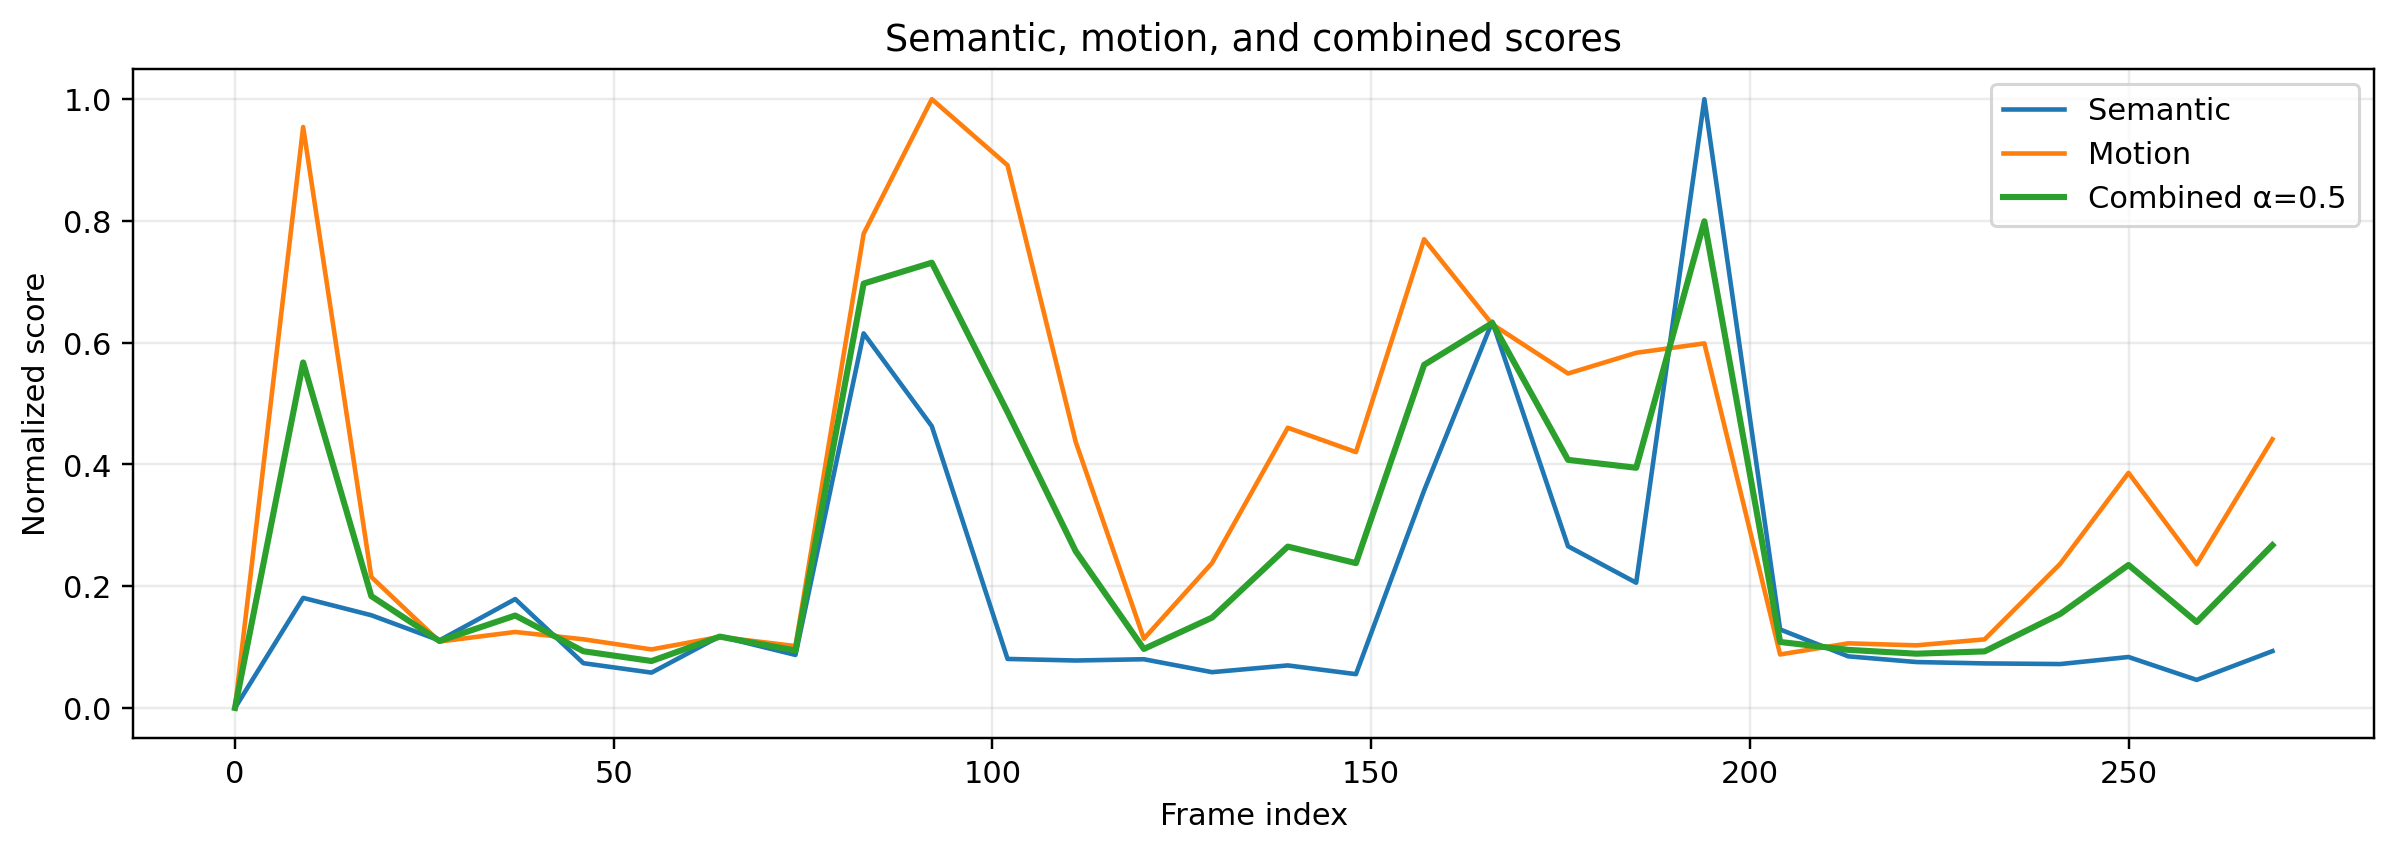

---

### 7. Duration S Distribution
`results/figures/duration_s_distribution.png`

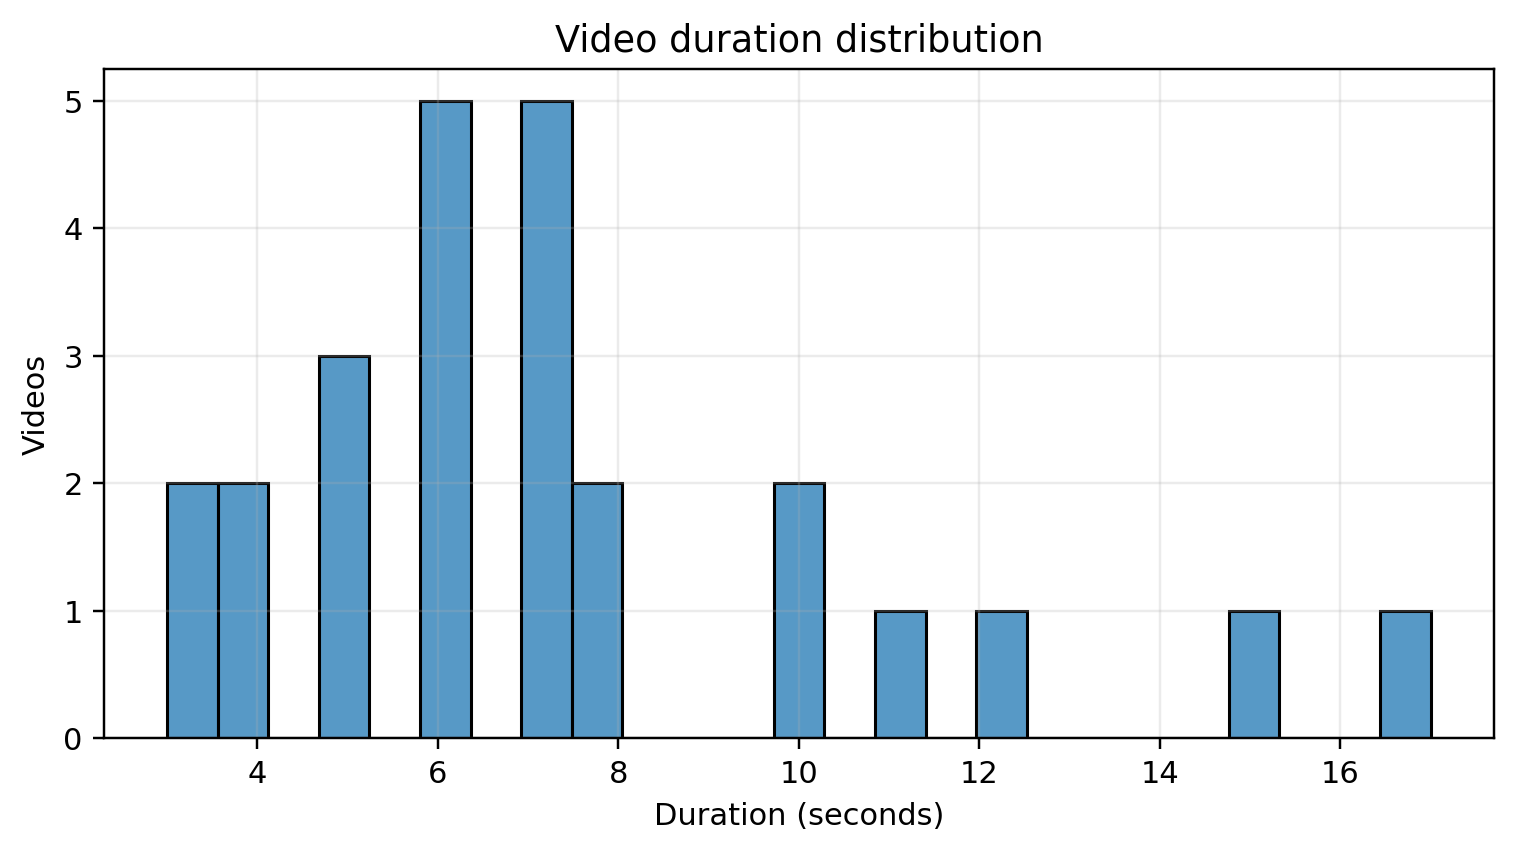

---

### 8. Fps Distribution
`results/figures/fps_distribution.png`

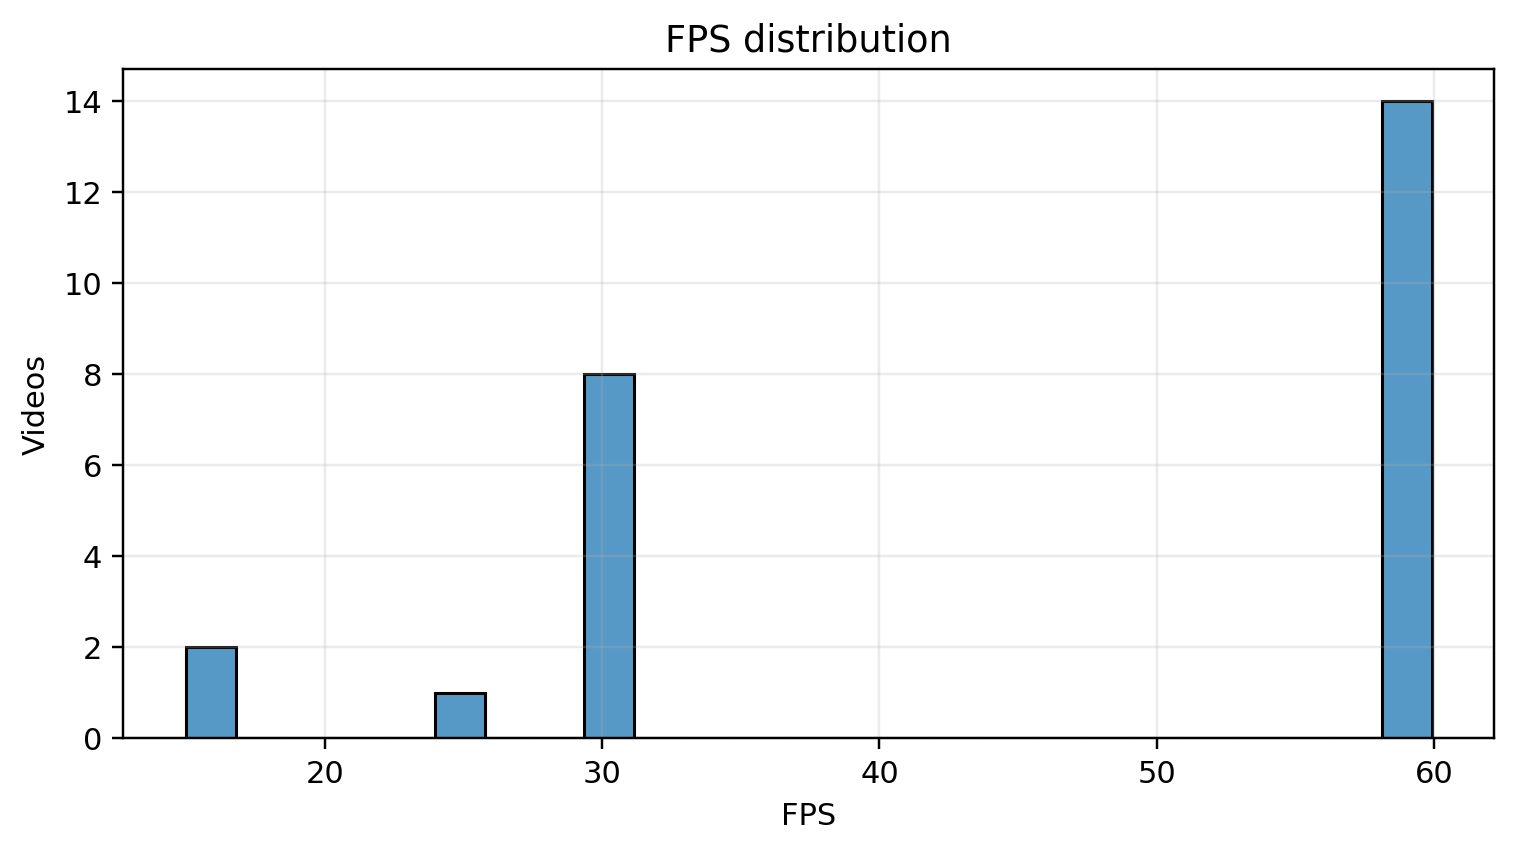

---

### 9. Frame Count Distribution
`results/figures/frame_count_distribution.png`

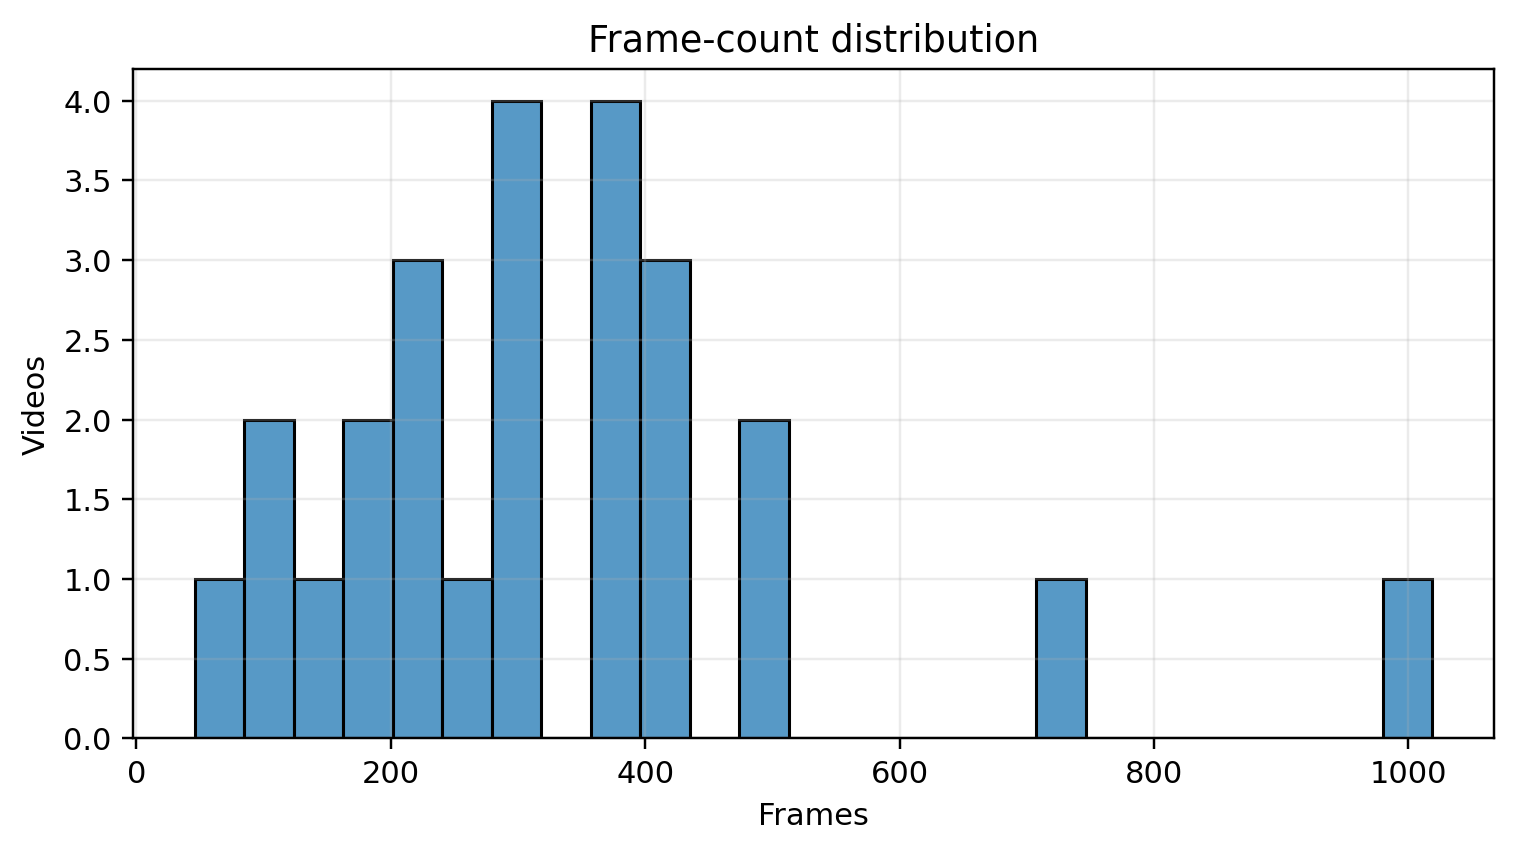

---

### 10. Motion Score Timeline
`results/figures/motion_score_timeline.png`

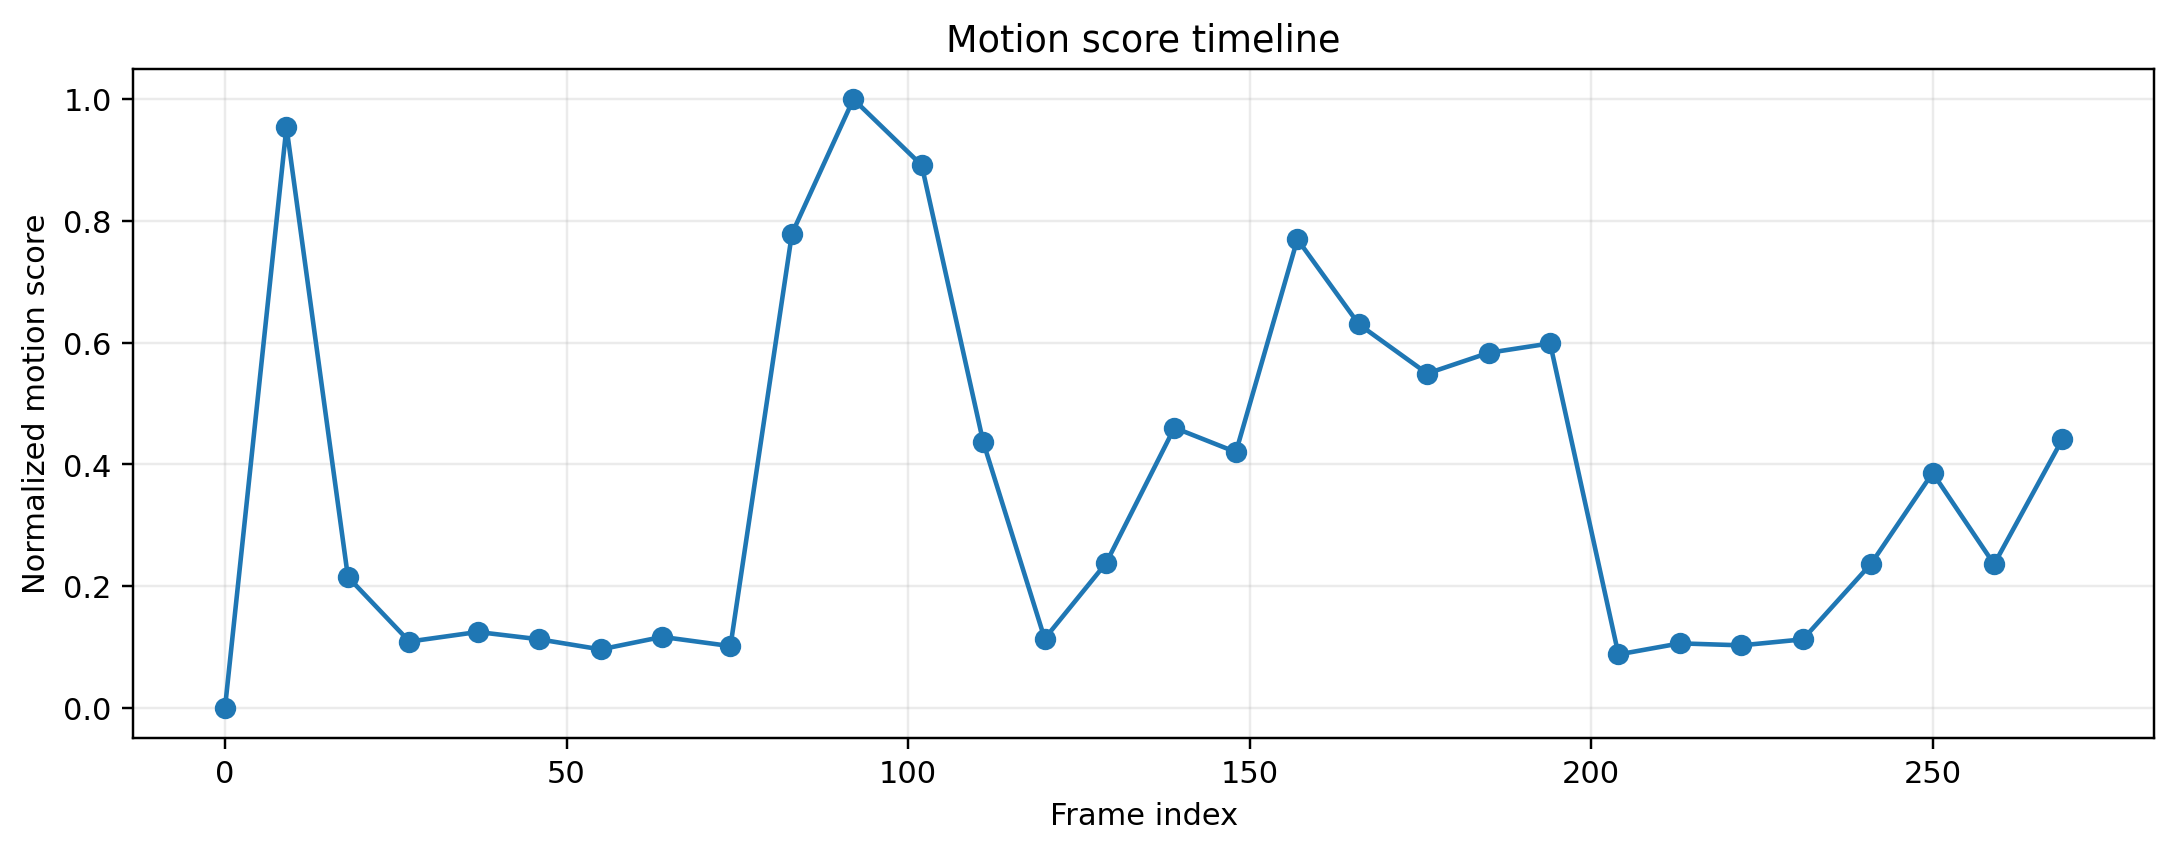

---

### 11. Random Frame Sampling
`results/figures/random_frame_sampling.png`

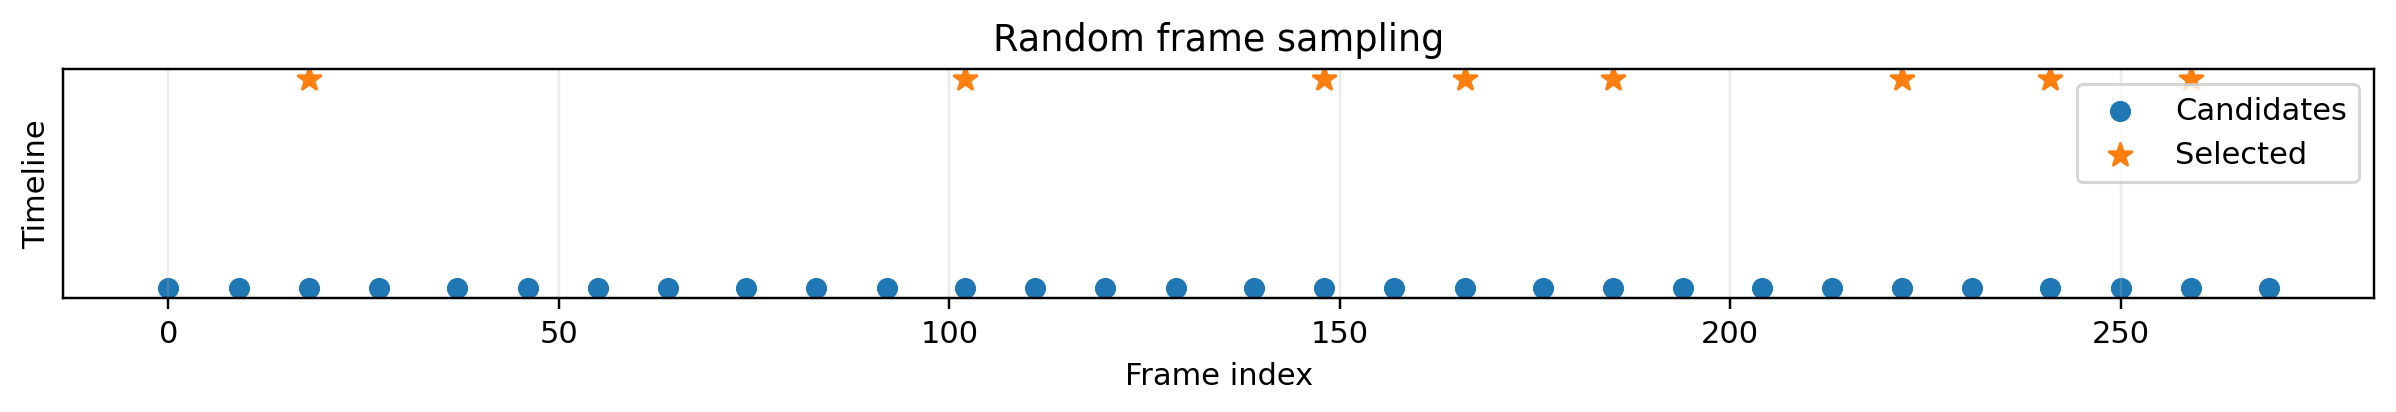

---

### 12. Resolution Distribution
`results/figures/resolution_distribution.png`

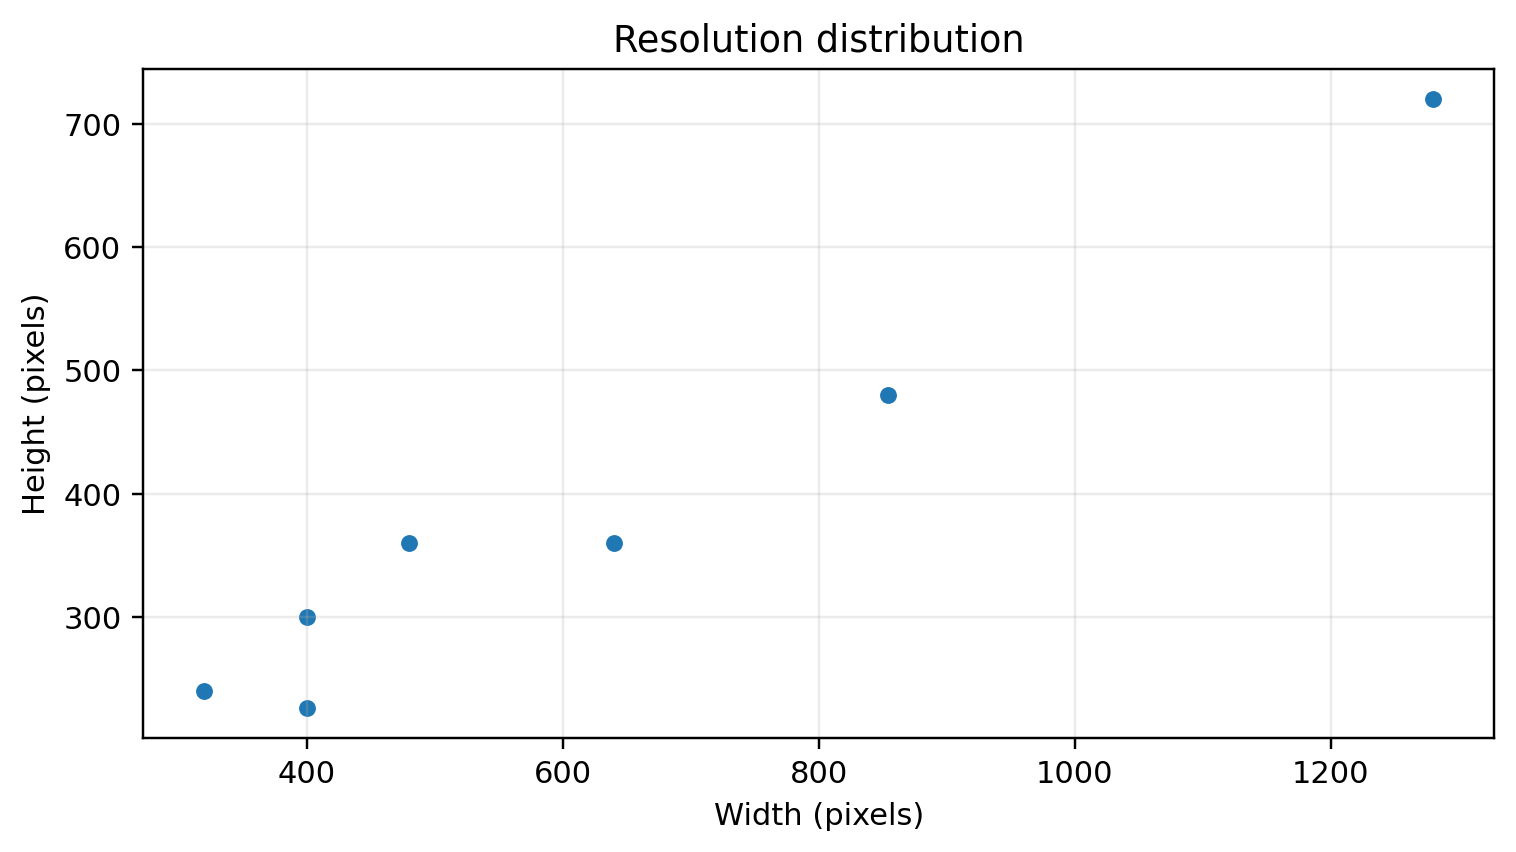

---

### 13. Semantic Score Timeline
`results/figures/semantic_score_timeline.png`

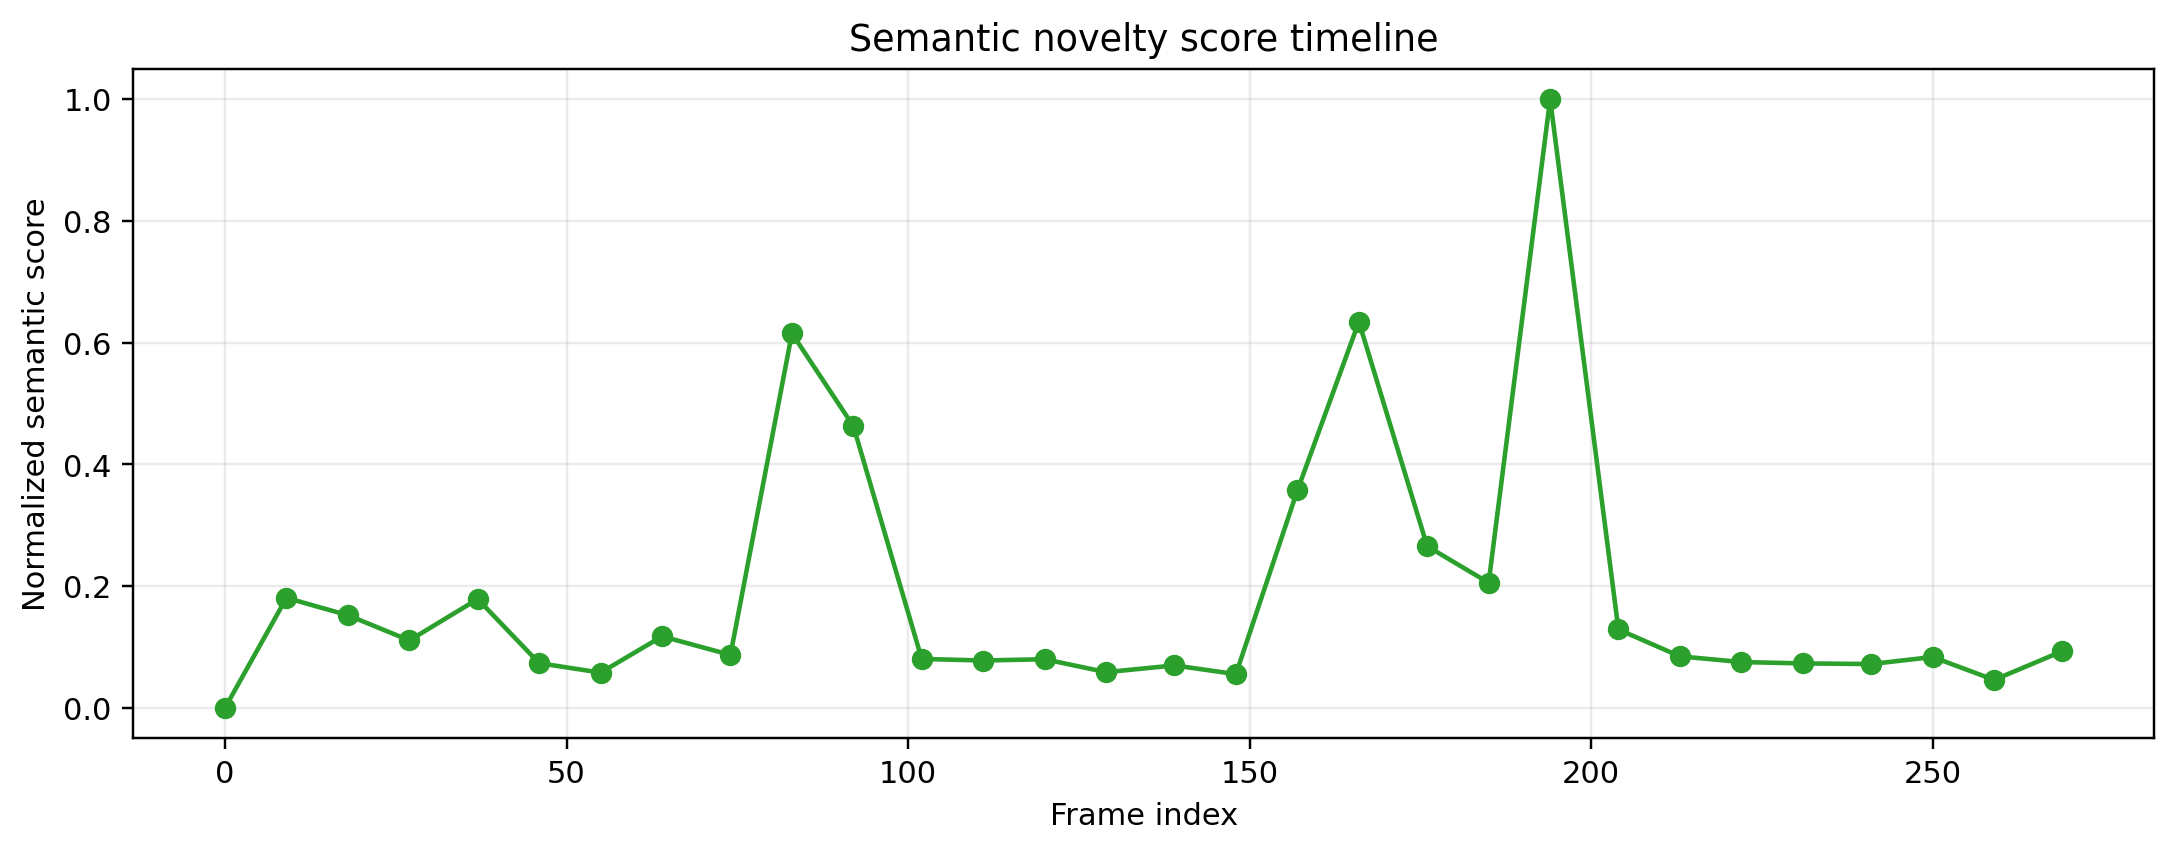

---

### 14. Top Words
`results/figures/top_words.png`

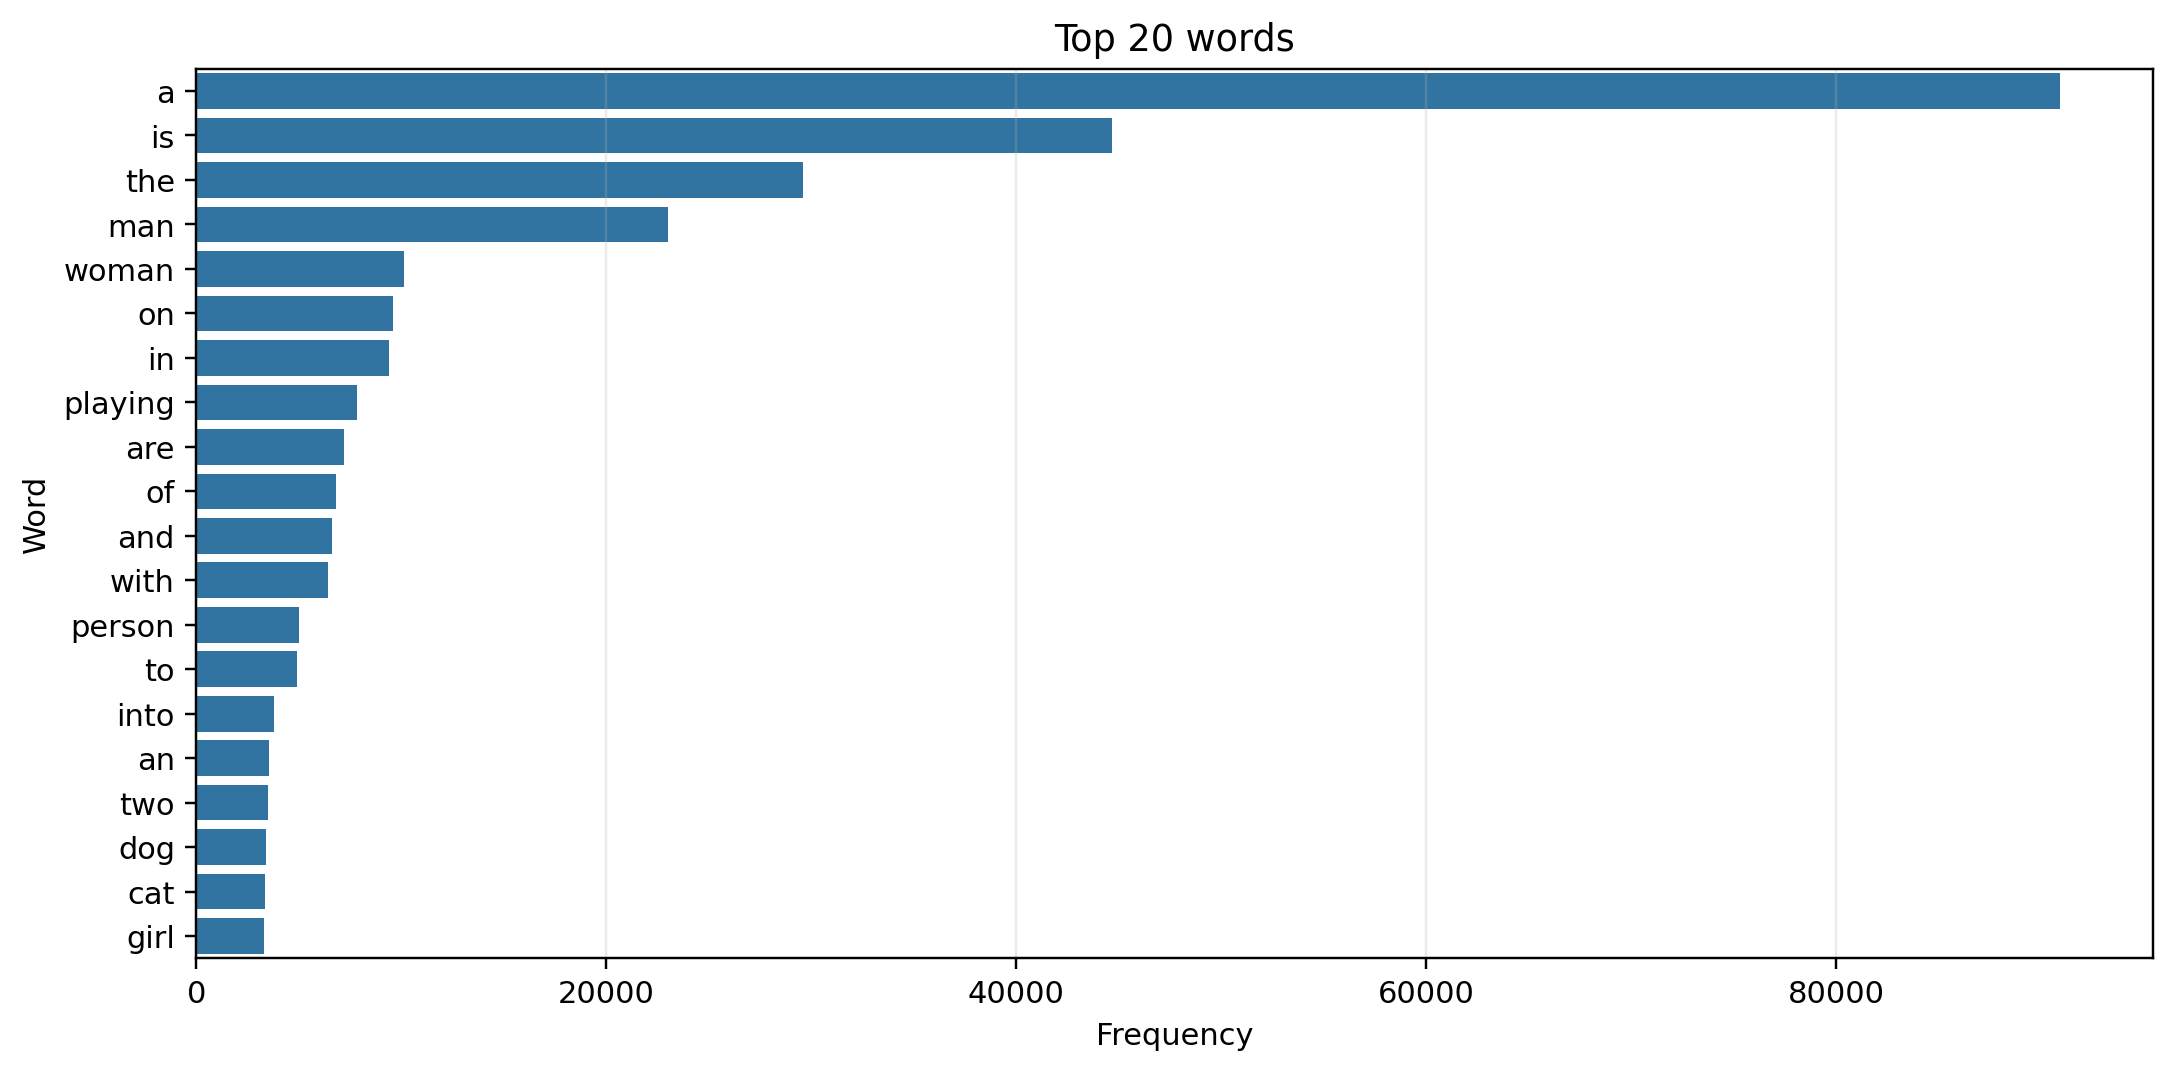

---

### 15. Uniform Frame Sampling
`results/figures/uniform_frame_sampling.png`

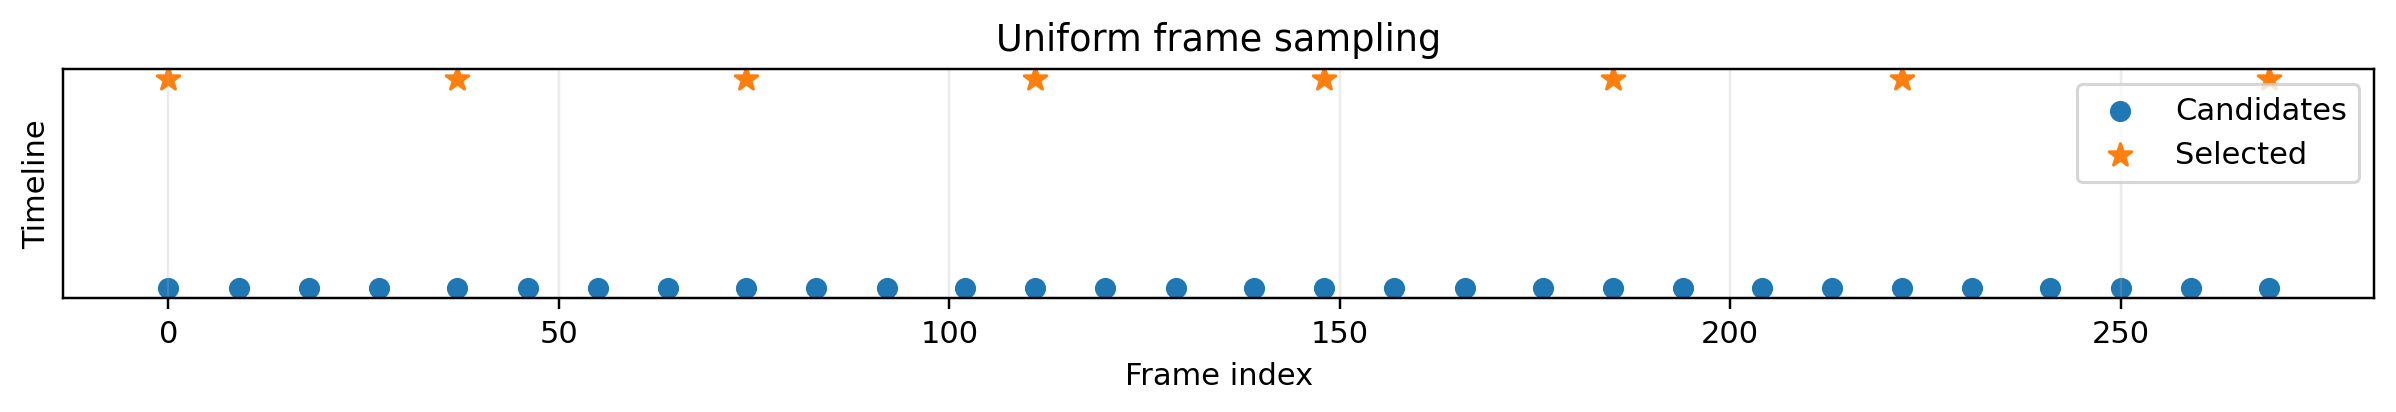

---

### 16. Word Frequency Distribution
`results/figures/word_frequency_distribution.png`

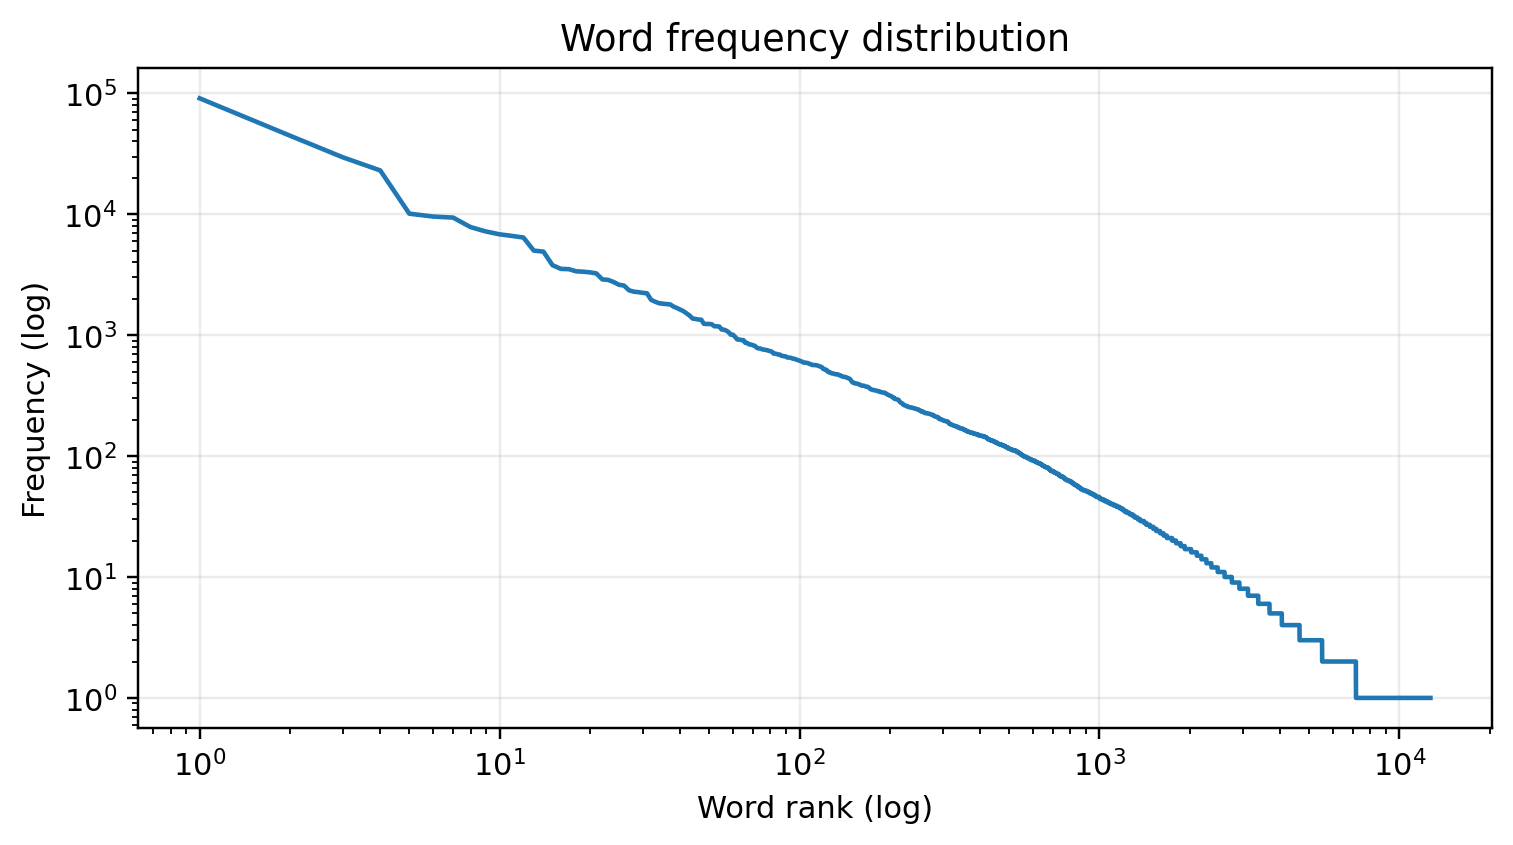

---

### 17. Wordcloud
`results/figures/wordcloud.png`

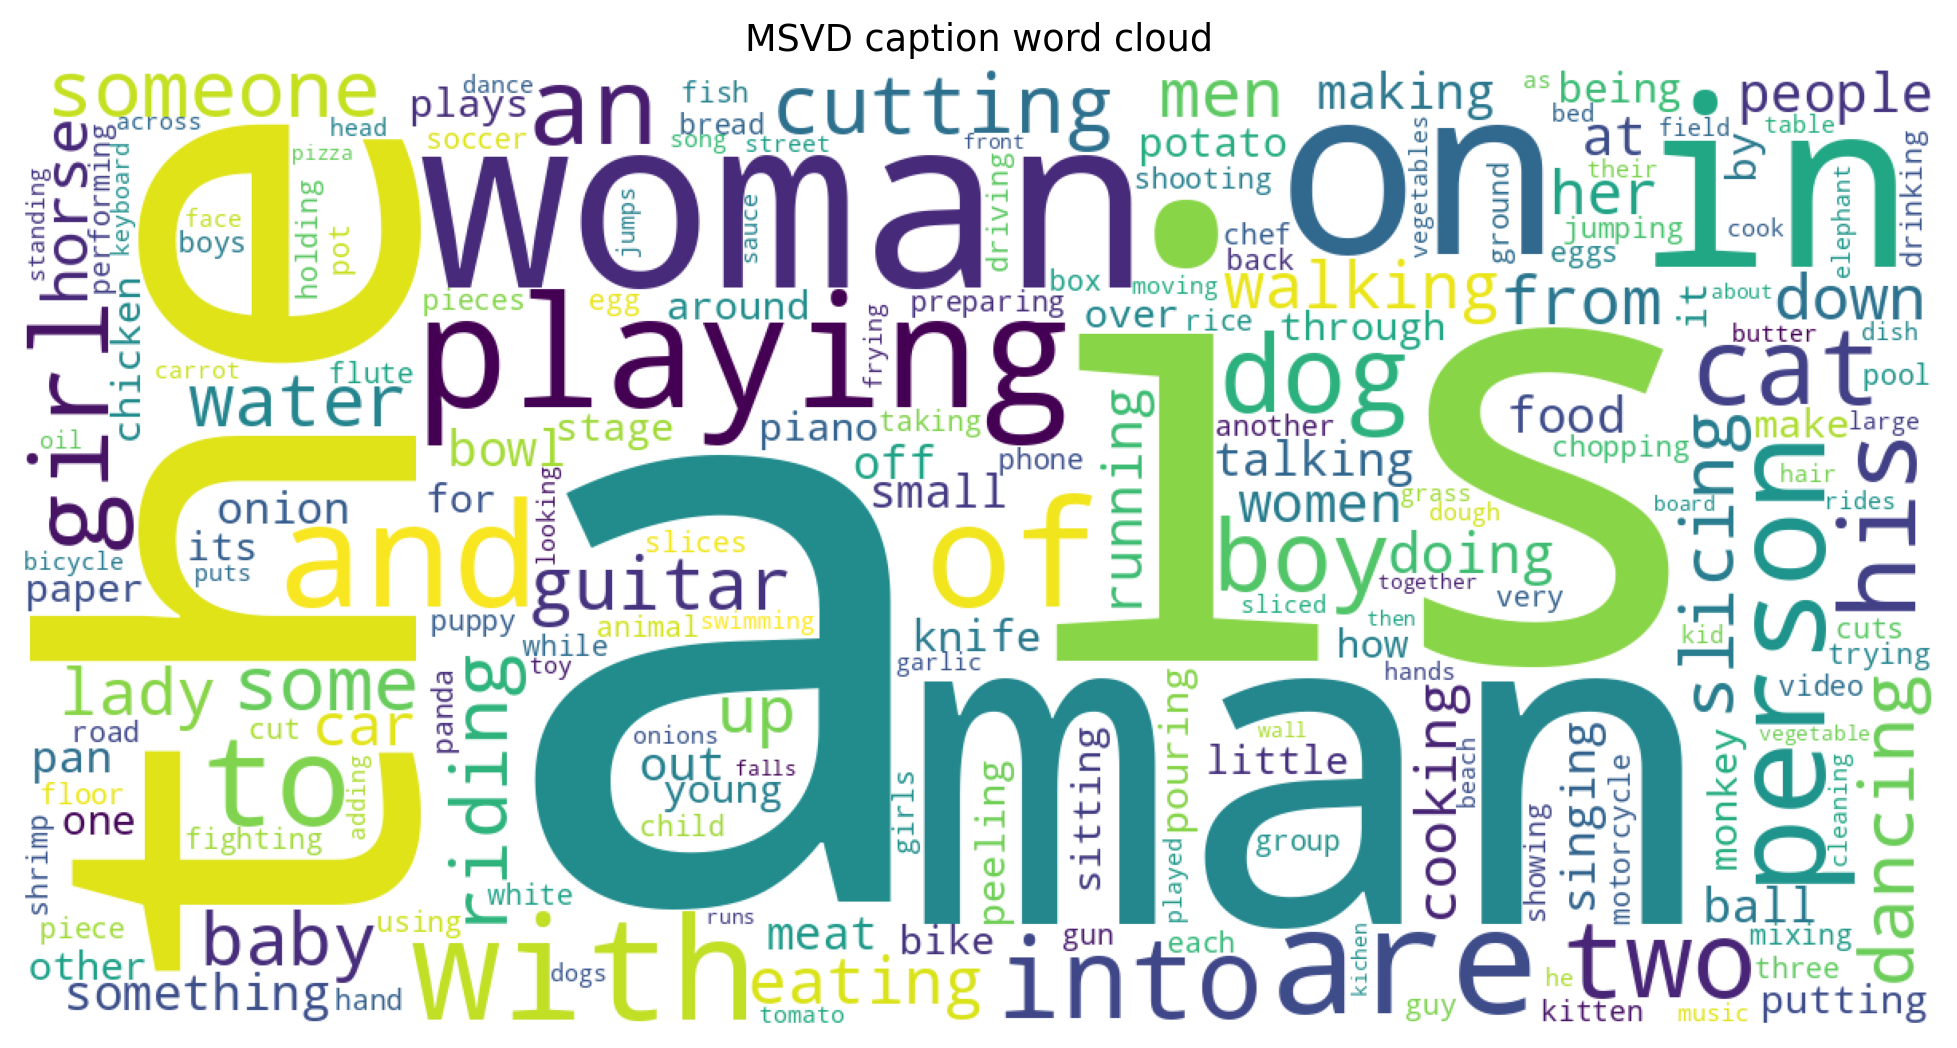

---

In [43]:
from IPython.display import (
    display,
    Image as IPythonImage,
    SVG,
    Markdown,
)

if "graph_files" not in globals():
    raise RuntimeError(
        "Run the graph-discovery cell first."
    )

if not graph_files:
    print("No graphs are available to display.")

for index, path in enumerate(graph_files, start=1):
    relative_path = path.relative_to(OUT)

    display(Markdown(
        f"### {index}. {path.stem.replace('_', ' ').title()}\n"
        f"`{relative_path}`"
    ))

    suffix = path.suffix.lower()

    if suffix in {".png", ".jpg", ".jpeg"}:
        display(IPythonImage(
            filename=str(path),
            width=1000,
        ))

    elif suffix == ".svg":
        display(SVG(filename=str(path)))

    elif suffix == ".pdf":
        display(Markdown(
            f"PDF figure saved at `{path}`. "
            "Open it from the Colab Files panel."
        ))

    display(Markdown("---"))

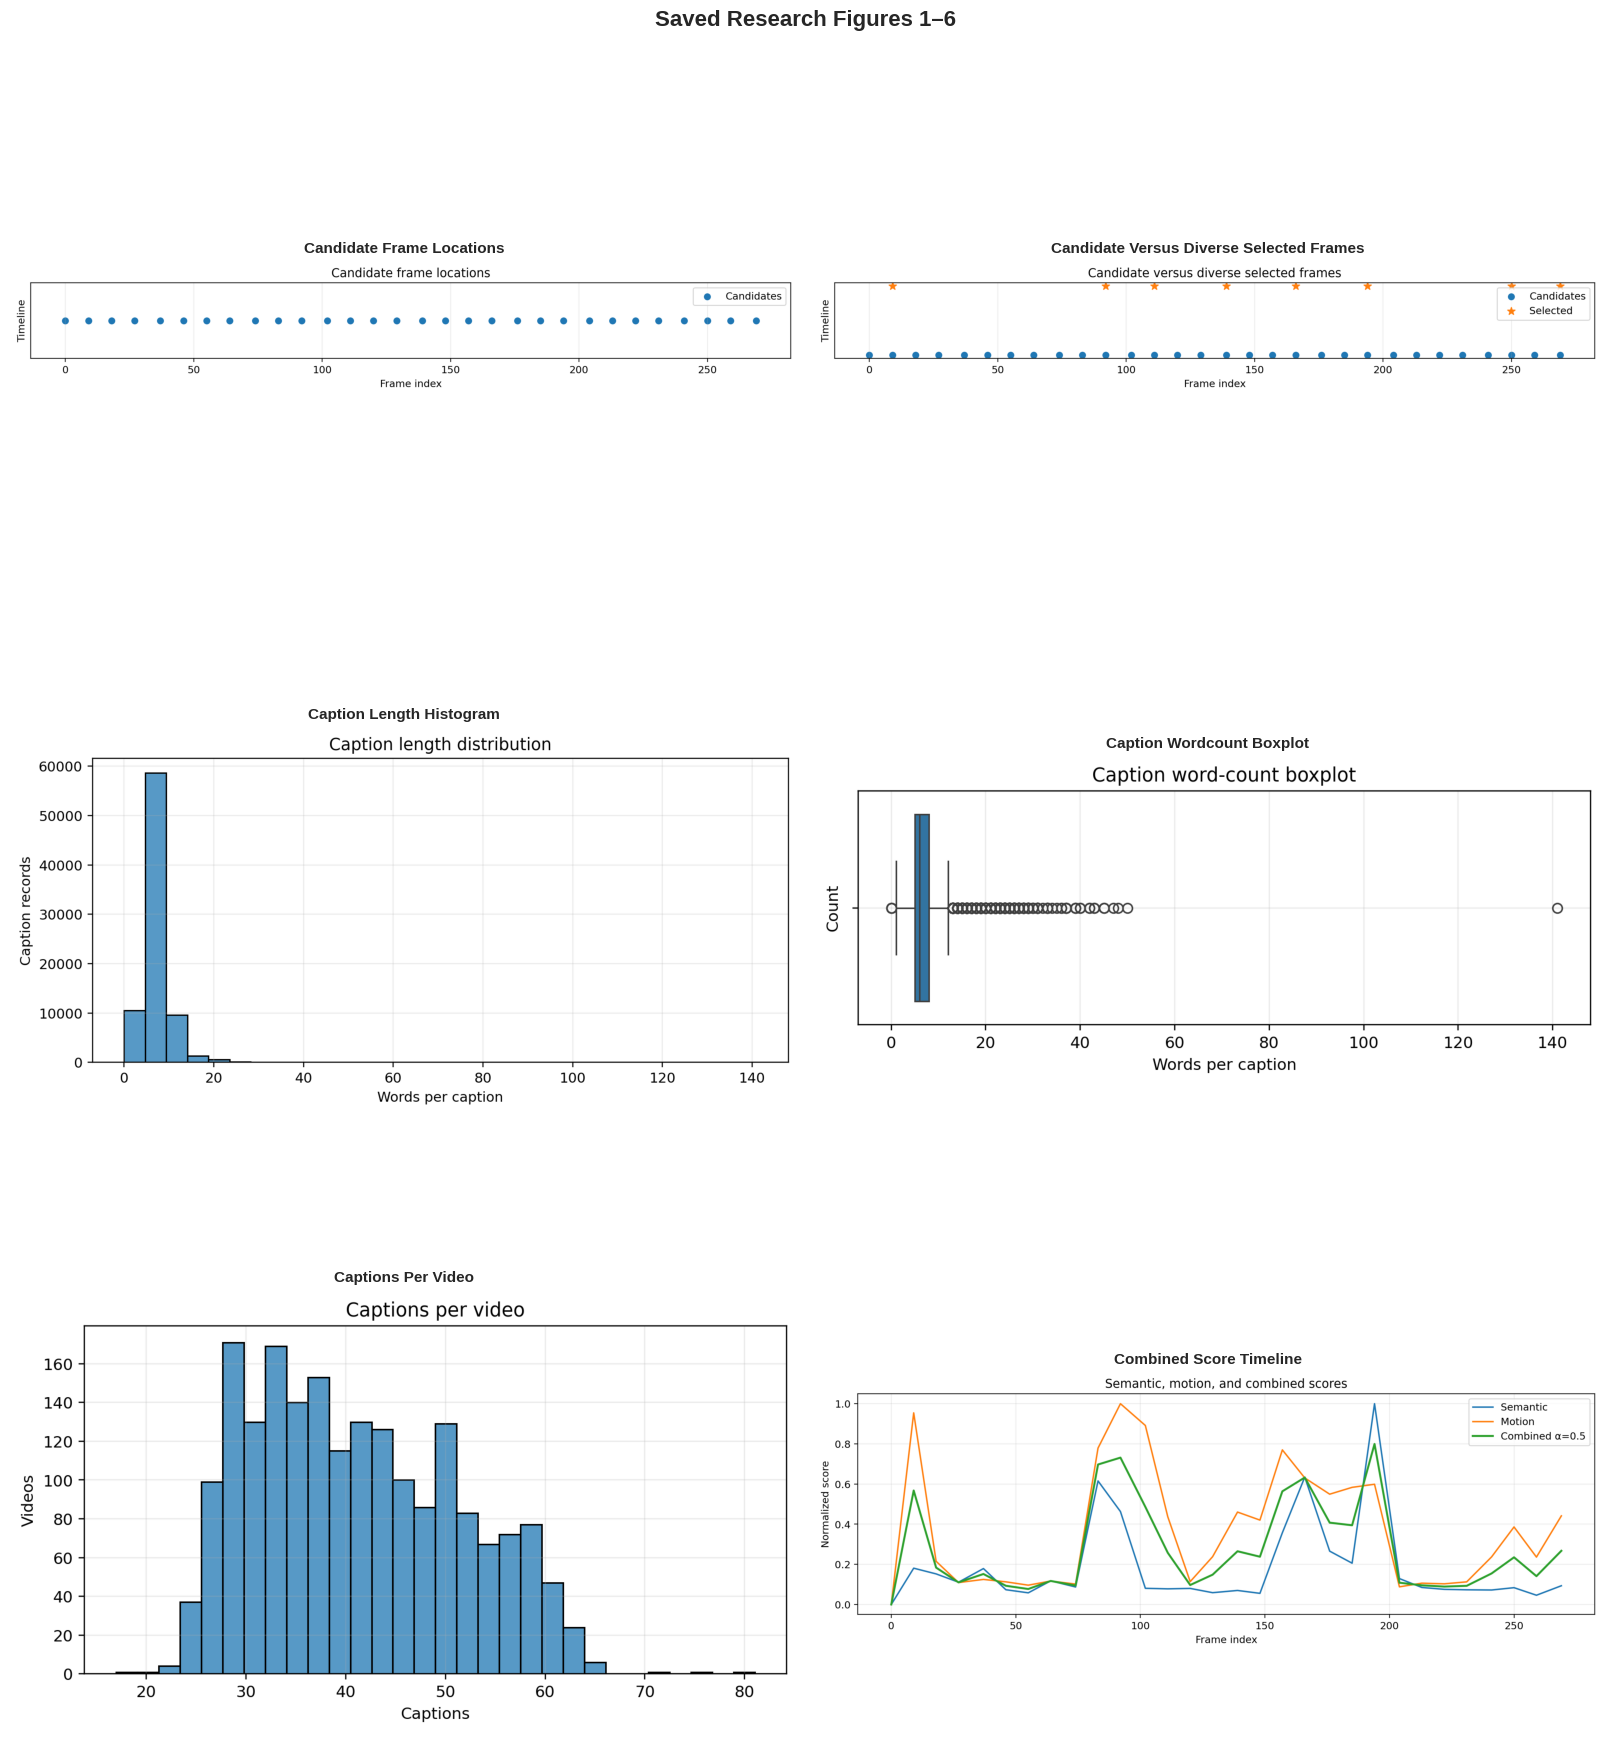

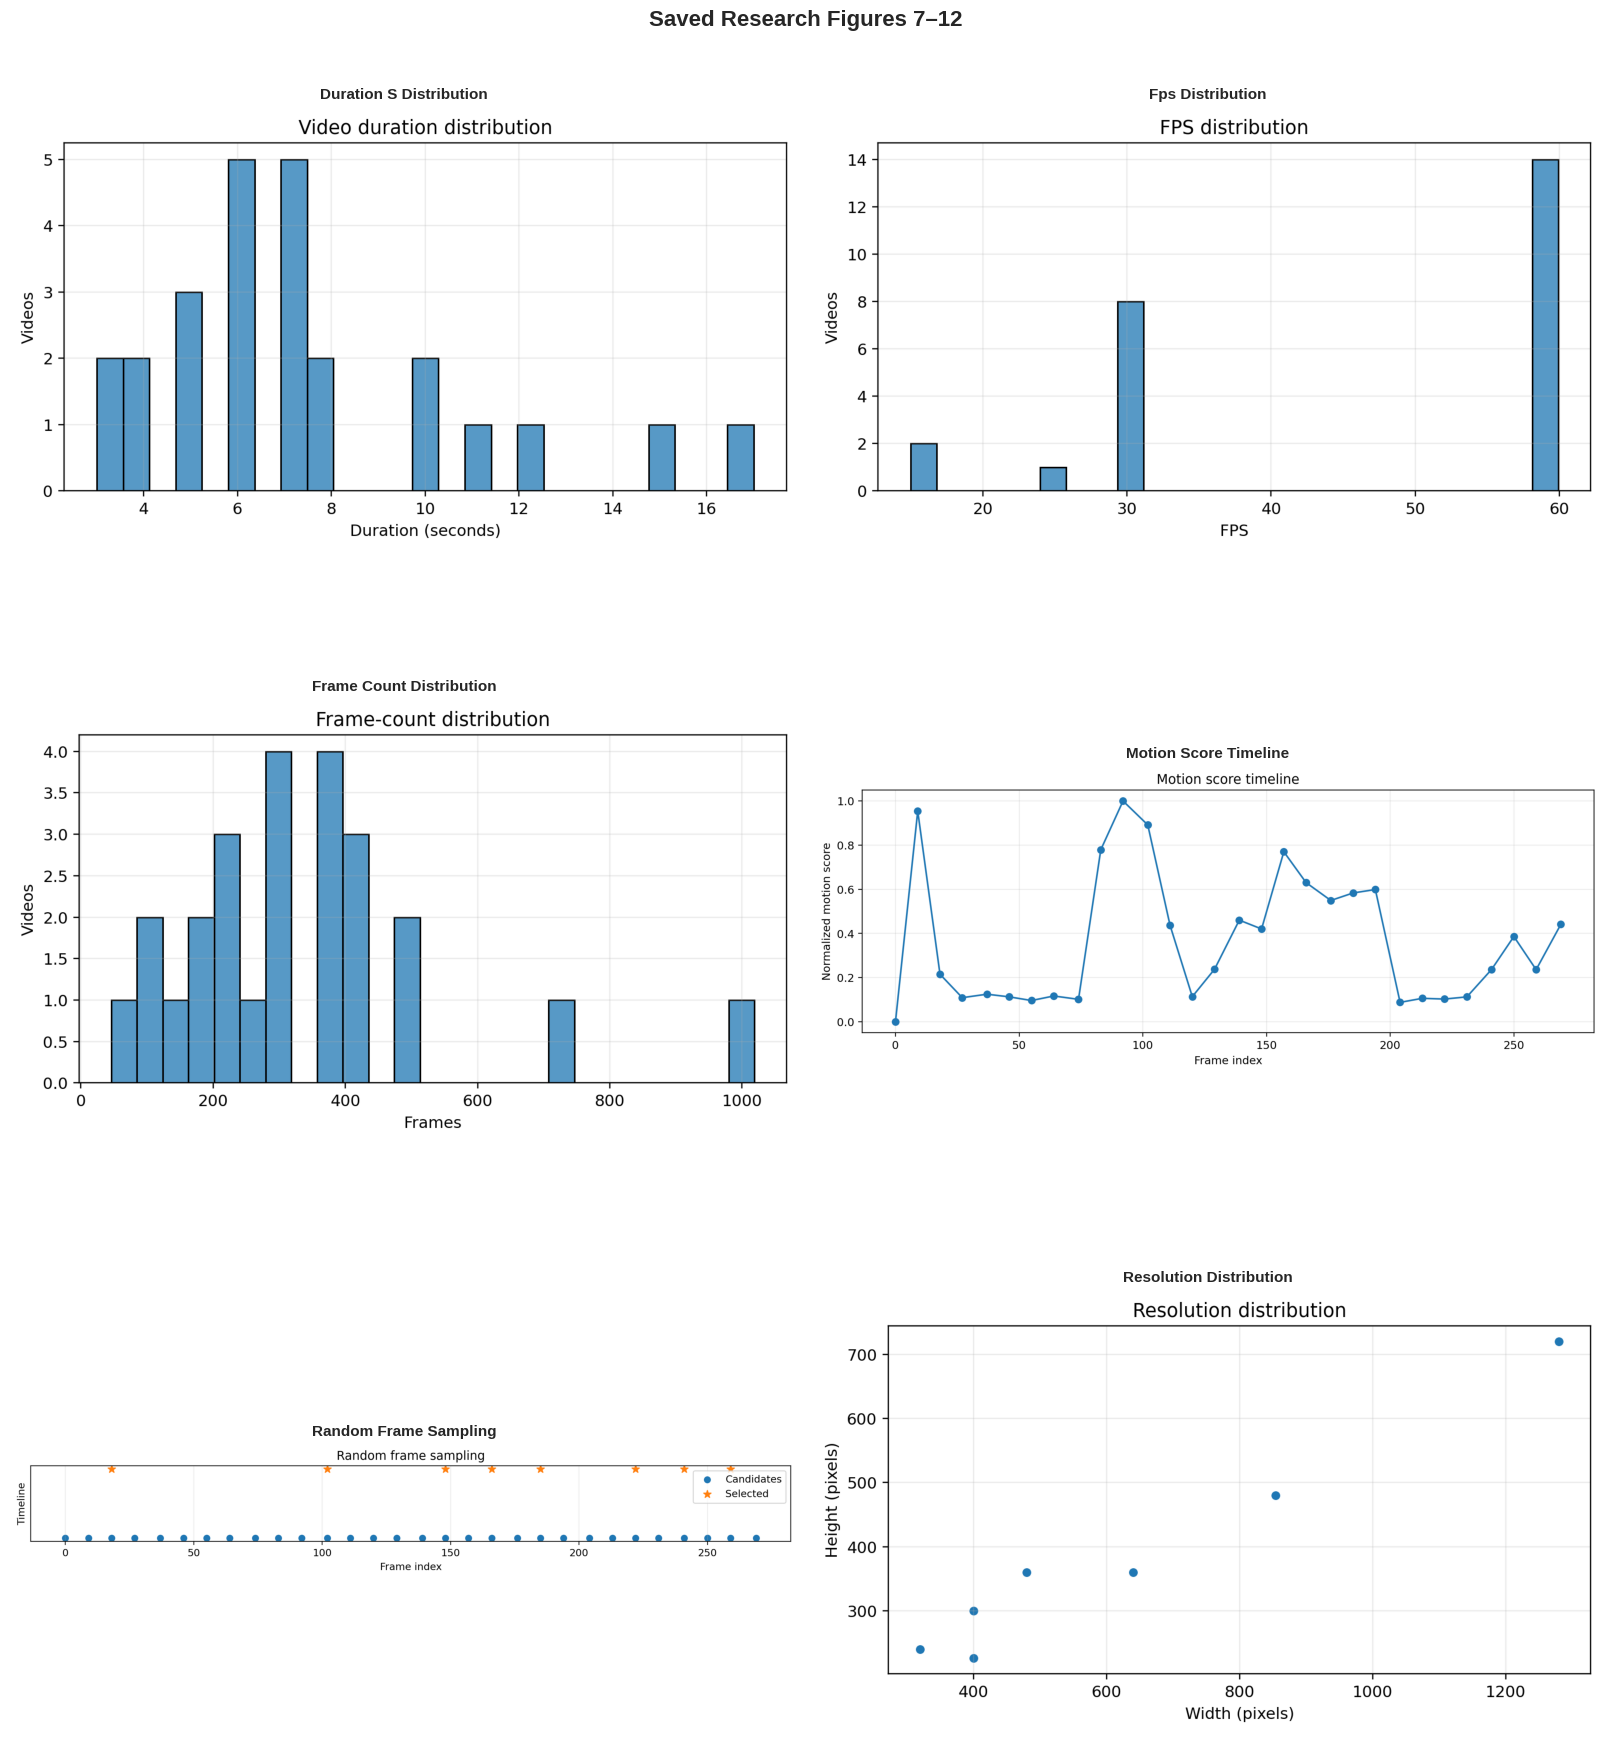

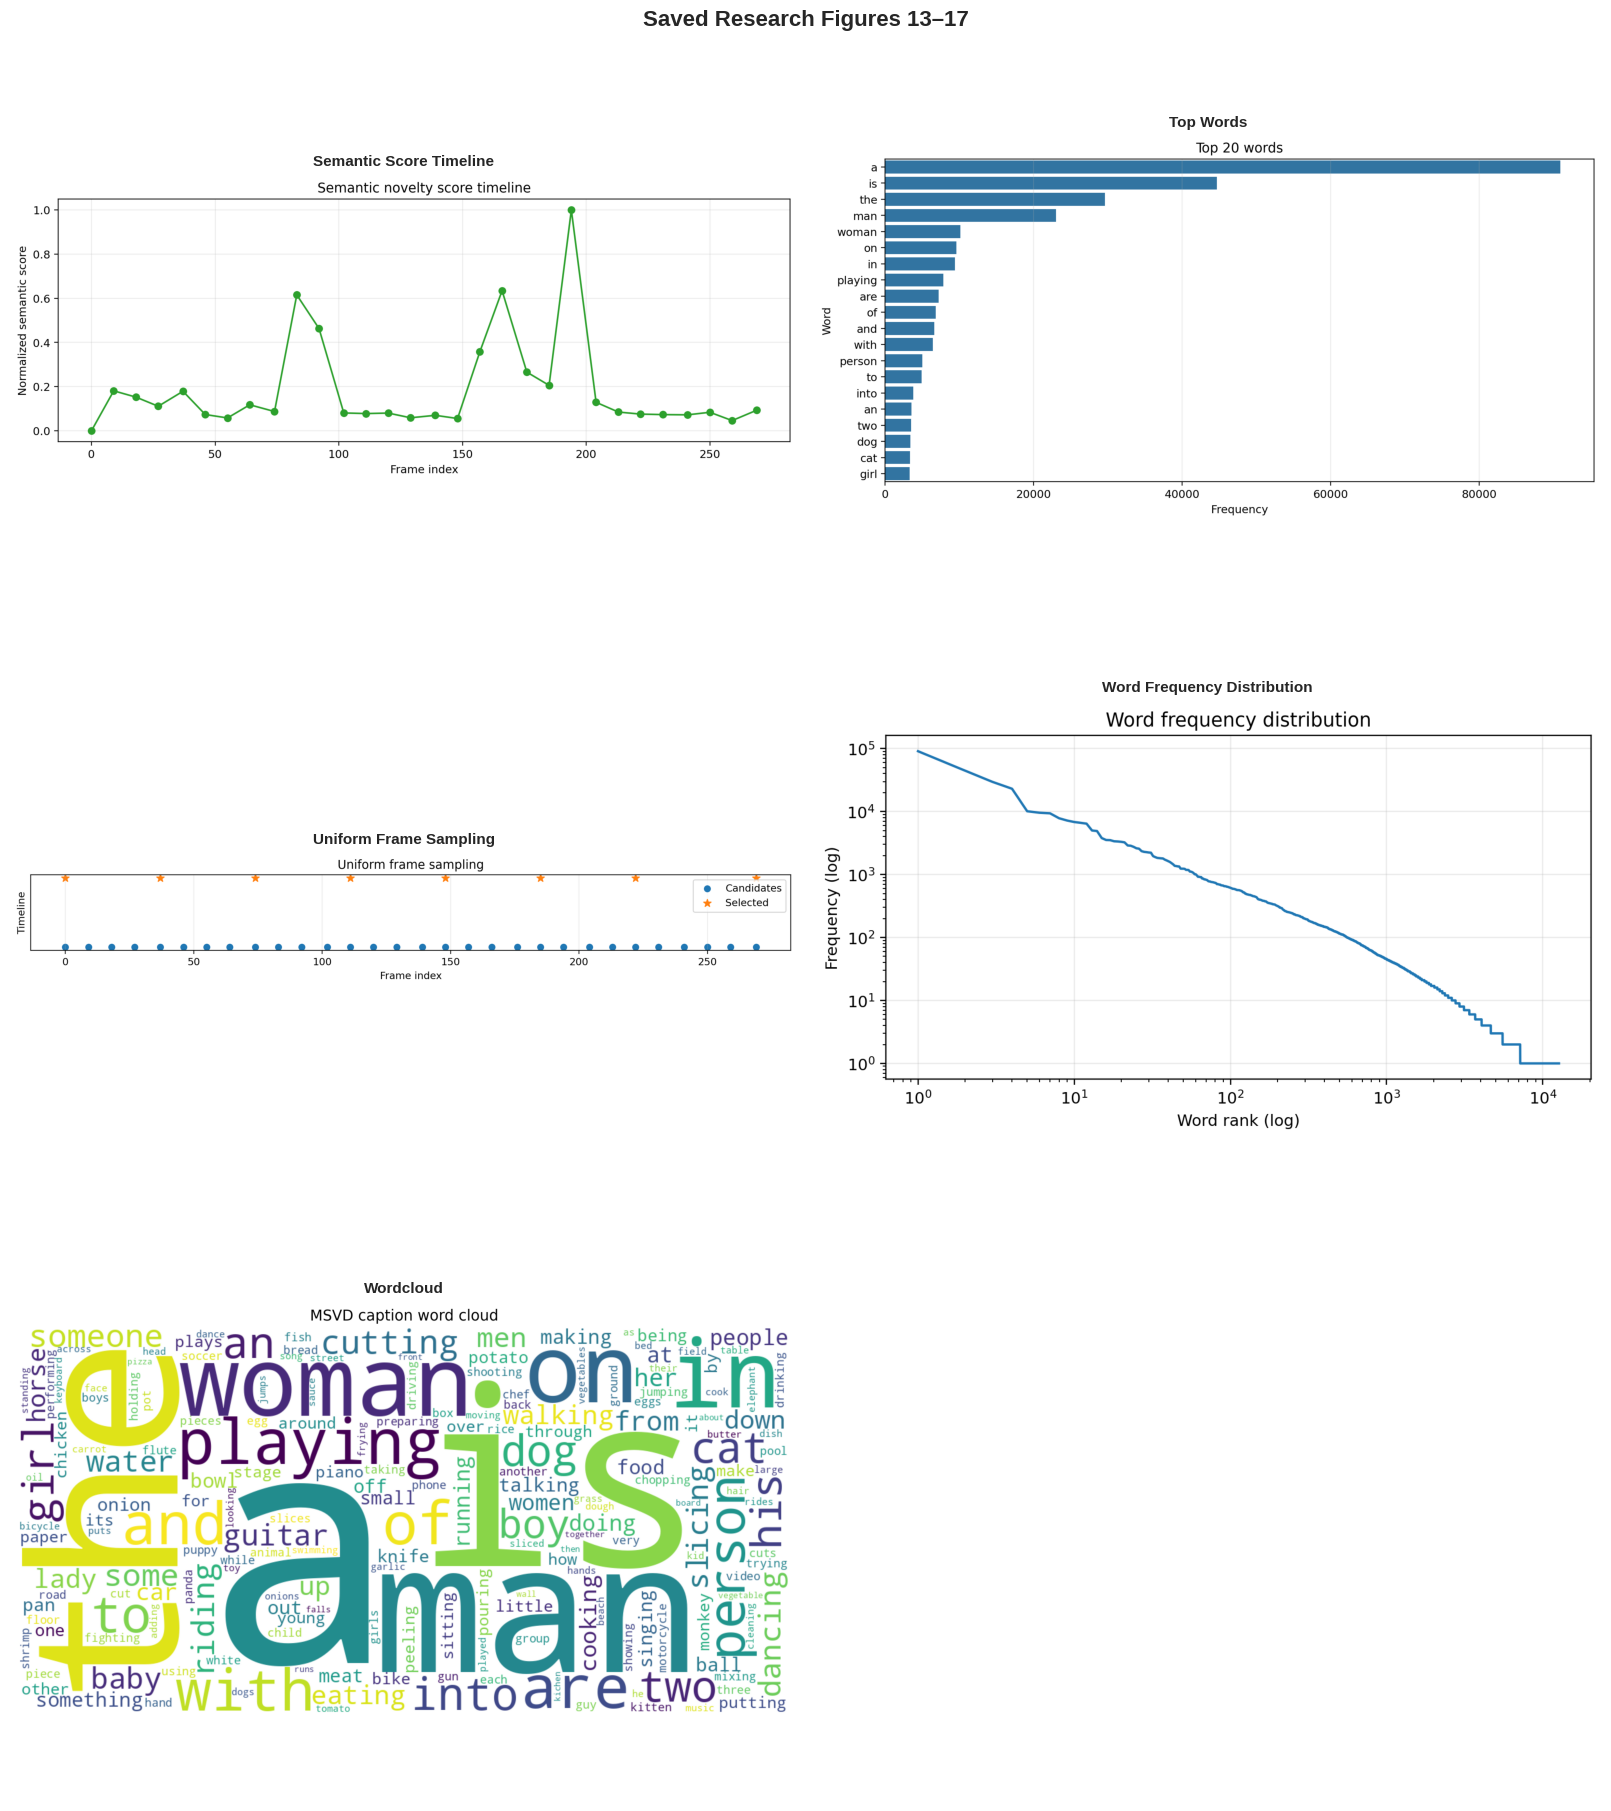

In [44]:
from PIL import Image
import matplotlib.pyplot as plt
import math

raster_graphs = [
    path
    for path in graph_files
    if path.suffix.lower() in {
        ".png",
        ".jpg",
        ".jpeg",
    }
]

if not raster_graphs:
    print("No PNG/JPG figures are available for the gallery.")

else:
    images_per_page = 6
    columns = 2

    for page_start in range(
        0,
        len(raster_graphs),
        images_per_page,
    ):
        page_files = raster_graphs[
            page_start:page_start + images_per_page
        ]

        rows = math.ceil(len(page_files) / columns)

        figure, axes = plt.subplots(
            rows,
            columns,
            figsize=(16, 6 * rows),
            squeeze=False,
            constrained_layout=True,
        )

        for axis, path in zip(
            axes.flat,
            page_files,
        ):
            with Image.open(path) as image:
                axis.imshow(image.convert("RGB"))

            axis.set_title(
                path.stem.replace("_", " ").title(),
                fontsize=11,
                fontweight="bold",
            )
            axis.axis("off")

        for axis in axes.flat[len(page_files):]:
            axis.axis("off")

        figure.suptitle(
            (
                f"Saved Research Figures "
                f"{page_start + 1}–"
                f"{page_start + len(page_files)}"
            ),
            fontsize=16,
            fontweight="bold",
        )

        plt.show()
        plt.close(figure)

# 24. Conclusions and Research Interpretation

In [36]:
print("""Interpret results only after the planned validation selection and a single frozen-configuration test pass.
- Compare adaptive selection with uniform at equal frame budgets; report measured efficiency rather than inferred savings.
- Treat CIDEr/SPICE as optional when their Java/package dependencies cannot be reproduced, and state that limitation.
- Report the selected alpha, seed, splits, model checkpoint, and all failed/corrupted videos from saved artifacts.
- Do not claim a method wins from qualitative examples alone; those examples are fixed-seed random test samples.""")


Interpret results only after the planned validation selection and a single frozen-configuration test pass.
- Compare adaptive selection with uniform at equal frame budgets; report measured efficiency rather than inferred savings.
- Treat CIDEr/SPICE as optional when their Java/package dependencies cannot be reproduced, and state that limitation.
- Report the selected alpha, seed, splits, model checkpoint, and all failed/corrupted videos from saved artifacts.
- Do not claim a method wins from qualitative examples alone; those examples are fixed-seed random test samples.
